# Auto-Tuning Gray-Scott Using Julia

# Setup

The setup is similar to the KernelAbstractions tutorial. The cells below activate the project environment, install and load the packages, and select the backend; first set `DEV` below to match your hardware.

In [1]:
# Check that you are on the compute node
println("Running on node: ", gethostname())

Running on node: node002


In [2]:
# Pick your hardware: :NVIDIA, :AMD, :Metal, or :CPU
DEV = :NVIDIA

:NVIDIA

In [3]:
# if you like, you can force dark_mode (automatically detected if not set)
# dark_mode_override = false

In [4]:
include("setup_notebook.jl")

  Activating project at `~/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks`
     Project No packages added to or removed from `~/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
    Manifest No packages added to or removed from `~/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Manifest.toml`
     Project No packages added to or removed from `~/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
    Manifest No packages added to or removed from `~/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Manifest.toml`
   Resolving package versions...
     Project No packages added to or removed from `~/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
    Manifest No packages added to or removed from `~/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/Kern

with_live_tuning_plot (generic function with 1 method)

Let's check the packages are installed correctly and set the backend we'll work with.

In [5]:
Pkg.status()

Status `~/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [052768ef] CUDA v6.5.1
  [3da002f7] ColorTypes v0.12.5
  [7073ff75] IJulia v1.34.4
  [682c06a0] JSON v1.13.4
  [63c18a36] KernelAbstractions v0.10.5
  [d8e2316b] KernelTuner v1.1.0 `../../../../KernelTuner.jl`
  [dde4c033] Metal v1.12.0
  [91a5bcdd] Plots v1.41.7
  [92933f4c] ProgressMeter v1.13.0
  [6099a3de] PythonCall v0.9.37


In [6]:
if DEV == :NVIDIA
    using CUDA
    ArrayKA = CUDA.CuArray
    Backend = CUDA.CUDABackend()
    # @assert CUDA.functional()
    println("GPU Device: ", CUDA.name(CUDA.device()))
elseif DEV == :AMD
    using AMDGPU
    ArrayKA = AMDGPU.ROCArray
    Backend = AMDGPU.ROCBackend()
elseif DEV == :Metal
    using Metal
    ArrayKA = Metal.MtlArray
    Backend = Metal.MetalBackend()
elseif DEV == :CPU
    ArrayKA = Array
    Backend = CPU()
    @warn "Using CPU backend. This will be very slow and might not work for all use cases in this tutorial. Consider using a GPU backend."
else
    error("Unknown DEV = $DEV. Use :NVIDIA, :AMD, :Metal, or :CPU.")
end

┌ Warning: CUDA runtime library `libcublasLt.so.13` was loaded from a system path, `/cm/shared/apps/cuda13.0/toolkit/13.0/targets/x86_64-linux/lib/libcublasLt.so.13`.
│ This may cause errors.
│ 
│ If you're running under a profiler, this situation is expected. Otherwise,
│ ensure that your library path environment variable (e.g., `PATH` on Windows
│ or `LD_LIBRARY_PATH` on Linux) does not include CUDA library paths.
│ 
│ In any other case, please file an issue.
└ @ CUDACore /var/scratch/fjwillem/.julia/packages/CUDACore/gfTex/src/initialization.jl:208
┌ Warning: CUDA runtime library `libcusparse.so.12` was loaded from a system path, `/cm/shared/apps/cuda13.0/toolkit/13.0/targets/x86_64-linux/lib/libcusparse.so.12`.
│ This may cause errors.
│ 
│ If you're running under a profiler, this situation is expected. Otherwise,
│ ensure that your library path environment variable (e.g., `PATH` on Windows
│ or `LD_LIBRARY_PATH` on Linux) does not include CUDA library paths.
│ 
│ In any other case

GPU Device: NVIDIA RTX A6000


# 1. The Gray-Scott Reaction-Diffusion Model

The Gray-Scott Reaction-Diffusion model is a mathematical model used to describe how two interacting substances, typically denoted as $U$ and $V$, evolve over time in a spatial domain. This model captures the combined effects of chemical reactions and diffusion, leading to complex pattern formations such as spots, stripes, and waves, which resemble natural phenomena like animal skin patterns or chemical reactions in a petri dish. 

## The Kernel

This kernel is a relatively simple one; for more information on this implementation see [the KernelAbstractions tutorial](). We'll start by adding the workgroup size as tunable parameters. For this, use Julia's `::Val{} where` syntax. This compiles to a constant and a default can be provided so your kernel is still completely executable outside of autotuning contexts.


In [7]:
using KernelAbstractions

# 5-point Laplacian, same as the reference CPU implementation
@inline function laplacian(A, x, y, dx)
    @inbounds DAx = (A[x-1, y] - (2 * A[x, y]) + A[x+1, y]) / dx
    @inbounds DAy = (A[x, y-1] - (2 * A[x, y]) + A[x, y+1]) / dx
    return DAx + DAy
end

# BX × BY is the workgroup size: Kernel Tuner passes each tunable parameter to the kernel as a `Val` argument
@kernel function gs_gpu_kernel!(Uout, Vout, @Const(U), @Const(V), D_u, D_v, F, k, dt, dx, nx, ny, noise,
        ::Val{BX} = Val(16), ::Val{BY} = Val(16)) where {BX, BY}
    x, y = @index(Global, NTuple)

    if (1 < x < nx) && (1 < y < ny)
        u = @inbounds U[x, y]
        v = @inbounds V[x, y]

        ΔU = laplacian(U, x, y, dx)
        ΔV = laplacian(V, x, y, dx)
        UVV = u * v * v
        Nr = noise == 0 ? zero(u) : noise * randn(Float32)
        DU = D_u * ΔU - UVV + F * (1 - u) + Nr
        DV = D_v * ΔV + UVV - (F + k) * v
        newU = u + DU * dt
        newV = v + DV * dt

        @inbounds Uout[x, y] = newU
        @inbounds Vout[x, y] = newV
    end
end

gs_gpu_kernel! (generic function with 4 methods)

Now that we have our kernel source code, it might be nice to see what it actually does. Don't worry about the implementation details of the cell below, they're just to draw a nice animation. 


In [8]:
function simulate_gs_gpu(n = 500 #=Grid size=#, nsteps = 10000 #=Number of iterations=# ;
                        init_multi = 0.5,
                        noise = 0.0f0,
                        D_u = 0.16f0,
                        D_v = 0.08f0,
                        F = 0.035f0,
                        k = 0.06f0,
                        dt = 1.0f0,
                        dx = 1.0f0,
                        plot_every = 500)

    U = Float32.(rand(0.0:0.001:0.1, n, n))
    V = zeros(Float32, n, n)

    n_mid = div(n, 2)
    U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(init_multi)
    V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

    U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
    U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
    KernelAbstractions.copyto!(Backend, U1, U)
    KernelAbstractions.copyto!(Backend, V1, V)
    KernelAbstractions.copyto!(Backend, U2, U)
    KernelAbstractions.copyto!(Backend, V2, V)

    kernel = gs_gpu_kernel!(Backend, (cld(n, 16), cld(n, 16)))
    readU, readV, writeU, writeV = U1, V1, U2, V2

    prog = Progress(div(nsteps, plot_every))
    plt = Plots.plot(title="Gray-Scott Model", xlabel="X", ylabel="Y")

    anim = Plots.@animate for t in 1:div(nsteps, plot_every)
        for _ in 1:plot_every
            kernel(writeU, writeV, readU, readV, D_u, D_v, F, k, dt, dx, n, n, noise, ndrange=(n, n))
            readU, readV, writeU, writeV = writeU, writeV, readU, readV
        end

        KernelAbstractions.copyto!(Backend, U, readU)
        KernelAbstractions.synchronize(Backend)

        next!(prog)
        Plots.heatmap!(plt, U, color=cgrad([:black, :blue, :white]), clims=extrema(U), title="Gray-Scott Model", dpi=110)
    end
    gif(anim, "gs_ka.gif"; fps=10)
end

simulate_gs_gpu (generic function with 3 methods)

Let's see our Gray-Scott Model in action:

Progress: 100%|█████████████████████████████████████████| Time: 0:01:16


 84.005397 seconds (432.38 M allocations: 14.577 GiB, 7.76% gc time, 35.71% compilation time: 25% of which was recompilation)


[ Info: Saved animation to /home/fjwillem/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/gs_ka.gif


Plots.AnimatedGif("/home/fjwillem/Code/julia-hpc-tutorial-sc26/02-Parallel-Programming/KernelTuner/solved_notebooks/gs_ka.gif")
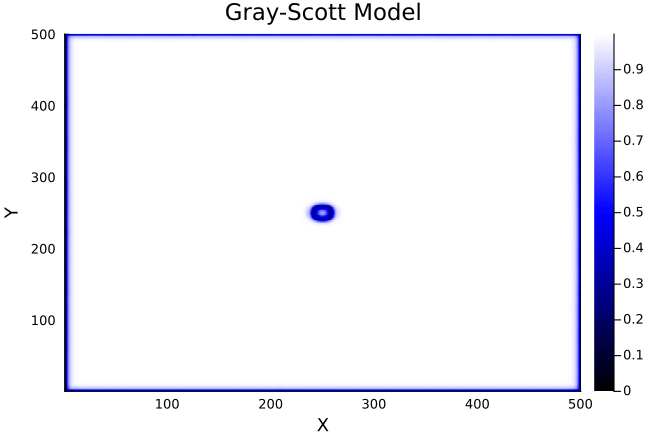

In [9]:
@time simulate_gs_gpu(500, 10000)

# 2. Autotuning the Kernel

We can see the kernel works. But can we improve its performance? Let's tune the workgroup sizes we added earlier and find out.
Now that we have our kernel source code in a file, we can get started on the autotuning! We start by generating some input data that we will use to run our GPU kernel.

In [10]:
# parameters
n = 500
init_multi = 0.5

U = Float32.(rand(0.0:0.001:0.1, n, n))
V = zeros(Float32, n, n)

n_mid = div(n, 2)
U[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(1.0 * init_multi)
V[n_mid-5:n_mid+5, n_mid-5:n_mid+5] .= Float32(0.5 * init_multi)

U1 = KernelAbstractions.allocate(Backend, Float32, n, n)
V1 = KernelAbstractions.allocate(Backend, Float32, n, n)
U2 = KernelAbstractions.allocate(Backend, Float32, n, n)
V2 = KernelAbstractions.allocate(Backend, Float32, n, n)
KernelAbstractions.copyto!(Backend, U1, U)
KernelAbstractions.copyto!(Backend, V1, V)
KernelAbstractions.copyto!(Backend, U2, U)
KernelAbstractions.copyto!(Backend, V2, V)

500×500 CuArray{Float32, 2, CUDACore.DeviceMemory}:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0

## 2.1. Tuning the workgroup size

We start with the simple kernel `gs_gpu_kernel!`, where every work-item computes exactly one grid point. The only thing we can tune here is the **workgroup size**: how many work-items are grouped together, and in what shape (`block_size_x` × `block_size_y`).

Kernel Tuner uses `block_size_x` and `block_size_y` as the workgroup dimensions by default, and by default divides the problem size by them to get the number of workgroups, so we don't need to specify `grid_div_x`/`grid_div_y` here.

In [11]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("block_size_x", [8, 16, 32, 64, 128]),  # workgroup size along x
    ("block_size_y", [1, 2, 4, 8, 16]),      # workgroup size along y
]

results_wg, env_wg = KernelTuner.tune_kernel(
    "gs_gpu_kernel!",
    get_cell_by_tag("gs_gpu_kernel"),   # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    tune_params,
    # each workgroup covers (block_size_x) × (block_size_y) grid points
    grid_div_x=("block_size_x", 1), grid_div_y=("block_size_y", 1),
    lang="Julia",
    verbose=true,
)

best_wg = (env_wg["best_config"]["block_size_x"], env_wg["best_config"]["block_size_y"])

Using: NVIDIA RTX A6000
Searchspace has 24 configurations after restrictions.
block_size_x=8, block_size_y=1, time=0.166ms
block_size_x=8, block_size_y=2, time=0.168ms
block_size_x=8, block_size_y=4, time=0.164ms
block_size_x=8, block_size_y=8, time=0.173ms
block_size_x=8, block_size_y=16, time=0.174ms
block_size_x=16, block_size_y=1, time=0.174ms
block_size_x=16, block_size_y=2, time=0.179ms
block_size_x=16, block_size_y=4, time=0.187ms
block_size_x=16, block_size_y=8, time=0.180ms
block_size_x=16, block_size_y=16, time=0.164ms
block_size_x=32, block_size_y=1, time=0.165ms
block_size_x=32, block_size_y=2, time=0.166ms
block_size_x=32, block_size_y=4, time=0.171ms
block_size_x=32, block_size_y=8, time=0.167ms
block_size_x=32, block_size_y=16, time=0.169ms
block_size_x=64, block_size_y=1, time=0.165ms
block_size_x=64, block_size_y=2, time=0.168ms
block_size_x=64, block_size_y=4, time=0.171ms
block_size_x=64, block_size_y=8, time=0.168ms
block_size_x=64, block_size_y=16, time=0.173ms
blo

(8, 4)

While Kernel Tuner has printed the configurations as it evaluated them, we may be interested in more detailed results. Have a look at the values returned by `tune_kernel` and discover what they entail.

In [12]:
display(results_wg)
display(env_wg)

24-element Vector{Dict{String, Any}}:
 Dict("compile_time" => 10.60210494324565, "time" => 0.16587199691760665, "block_size_y" => 1, "verification_time" => 0, "benchmark_time" => 543.7222397886217, "times" => [0.1812479895306751, 0.17407999257557094, 0.15871999494265765, 0.16991999291349202, 0.15257600171025842, 0.16383999900426716, 0.17609600035939366], "block_size_x" => 8, "timestamp" => "2026-11-07 08:03:07.938056+00:00", "framework_time" => 227.44703229955508, "strategy_time" => 0.0…)
 Dict("compile_time" => 11.34604588150978, "time" => 0.16846399860999858, "block_size_y" => 2, "verification_time" => 0, "benchmark_time" => 904.6590682119131, "times" => [0.17305600340478122, 0.16998399223666638, 0.17305600340478122, 0.16588799189776182, 0.16588799189776182, 0.16383999900426716, 0.17212801321875304], "block_size_x" => 8, "timestamp" => "2026-11-07 08:03:08.854484+00:00", "framework_time" => 227.44703229955508, "strategy_time" => 0.0…)
 Dict("compile_time" => 11.396490037441254, "time

Dict{String, Any} with 13 entries:
  "compiler_options"        => Any[]
  "total_verification_time" => 0
  "overhead_time"           => 1929.17
  "total_compile_time"      => 299.334
  "iterations"              => 7
  "total_benchmark_time"    => 17868.7
  "device_name"             => "NVIDIA RTX A6000"
  "pci_bus_id"              => nothing
  "best_config"             => Dict{String, Any}("compile_time"=>11.3965, "time…
  "total_strategy_time"     => 0.0
  "uuid"                    => "49382d7d-5f0b-17f4-6f59-7be052de6b93"
  "total_framework_time"    => 5458.73
  "compute_capability"      => "86"

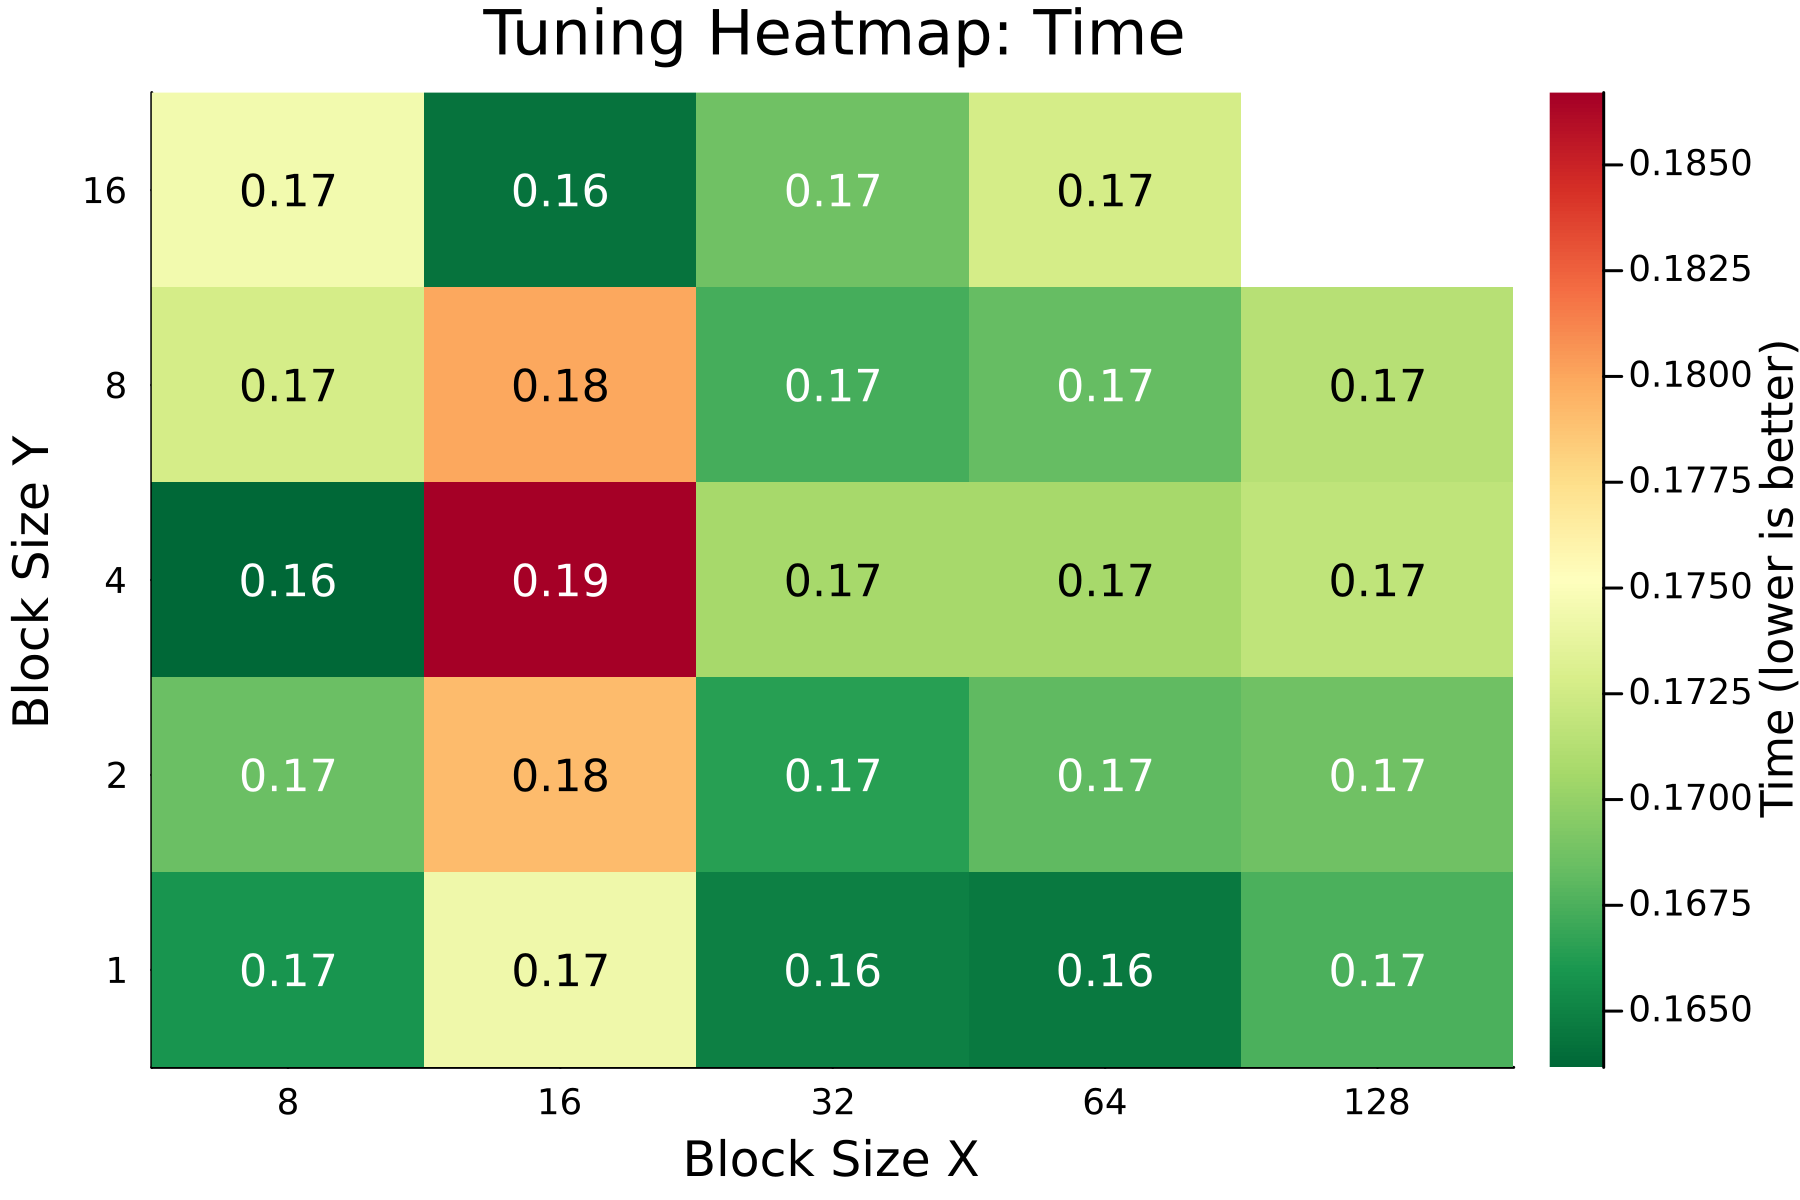

In [13]:
plot_heatmap_tuning_results(results_wg, "block_size_x", "block_size_y")

We can use the heatmap to analyze potentially interesting regions. 
What's going on with the missing configuration for `(128, 16)`? By default, Kernel Tuner applies a restriction that the product of the block sizes can not exceed 1024 as this is a hard limit for GPU programming models. We'll find out more about restrictions later on. 

## 2.2. Tuning the tile size

Of course we can do more than just tuning the workgroup sizes. Tiling, for example: a more advanced implementation that gives each work item a `P` × `Q` tile of the grid (`P` along `y`, `Q` along `x`). 
This is implemented in kernel `gs_gpu_kernel_tuned!`, where each work-item computes a `Q` × `P` tile of grid points. Each workgroup now covers `(block_size_x * Q) × (block_size_y * P)` grid points, so we tell Kernel Tuner to divide the problem size by both with `grid_div_x` and `grid_div_y`. 
The kernel also receives the workgroup size `BX` × `BY` as compile-time parameters: Kernel Tuner passes every tunable parameter to a Julia kernel as a `Val` argument, in the order they are defined, so the signature needs a slot for each of them (even though the workgroup size itself is set at launch).

In [14]:
using KernelAbstractions

# Fill per-work-item halo cache tile[q, p] = A[x1+q-2, y1+p-2] (out-of-bounds → zero).
# tile is `@private Float32 (Q + 2, P + 2)` — compile-time size from kernel parameters P, Q.
@inline function load_tile!(tile, A, x1, y1, nx, ny, ::Val{P}, ::Val{Q}) where {P, Q}
    @inbounds for q in 1:(Q + 2), p in 1:(P + 2)
        x = x1 + q - 2
        y = y1 + p - 2
        if 1 <= x <= nx && 1 <= y <= ny
            tile[q, p] = A[x, y]
        else
            tile[q, p] = zero(eltype(A))
        end
    end
    return
end

# Laplacian at tile indices (q, p) in 1:Q, 1:P — same 5-point formula as the CPU reference.
@inline function laplacian_tile(tile, q, p, dx)
    u = tile[q + 1, p + 1]
    @inbounds ux_m = tile[q, p + 1]
    @inbounds ux_p = tile[q + 2, p + 1]
    @inbounds uy_m = tile[q + 1, p]
    @inbounds uy_p = tile[q + 1, p + 2]
    ((ux_m - 2 * u + ux_p) + (uy_m - 2 * u + uy_p)) / dx
end

@kernel function gs_gpu_kernel_tiled!(Uout, Vout, @Const(U), @Const(V),
        D_u, D_v, F, k, dt, dx, nx, ny, noise, ::Val{P}, ::Val{Q}, ::Val{BX}, ::Val{BY}) where {P, Q, BX, BY}
    # Section 1: get indices
    i, j = @index(Global, NTuple)
    x1 = (i - 1) * Q + 1
    y1 = (j - 1) * P + 1

    # Section 2: allocate register memory and get data
    tileU = @private Float32 (Q + 2, P + 2)
    tileV = @private Float32 (Q + 2, P + 2)
    stepU = @private Float32 (Q, P)
    stepV = @private Float32 (Q, P)

    if (x1 < nx) && (x1 + Q > 2)
        load_tile!(tileU, U, x1, y1, nx, ny, Val(P), Val(Q))
        load_tile!(tileV, V, x1, y1, nx, ny, Val(P), Val(Q))

        # Section 3: calculate Laplacians (values → private step tile)
        for q in 1:Q, p in 1:P
            if (1 < x1 + q - 1 < nx) && (1 <  y1 + p - 1 < ny)
                u = tileU[q + 1, p + 1]
                v = tileV[q + 1, p + 1]
                ΔU = laplacian_tile(tileU, q, p, dx)
                ΔV = laplacian_tile(tileV, q, p, dx)
                UVV = u * v * v
                Nr = noise == 0 ? zero(u) : noise * randn(Float32)
                DU = D_u * ΔU - UVV + F * (1 - u) + Nr
                DV = D_v * ΔV + UVV - (F + k) * v
                stepU[q, p] = u + DU * dt
                stepV[q, p] = v + DV * dt
            end
        end

        # Section 4: global writes
        for q in 1:Q, p in 1:P
            x = x1 + q - 1
            y = y1 + p - 1
            if (1 < x < nx) && (1 < y < ny)
                @inbounds Uout[x, y] = stepU[q, p]
                @inbounds Vout[x, y] = stepV[q, p]
            end
        end
    end
end

gs_gpu_kernel_tiled! (generic function with 4 methods)

Next, we tune only the tile size `P` × `Q`, keeping the best workgroup size we found in step 1 fixed. 

In [15]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("P", [1, 2, 4, 8, 16]),                    # tile size per work-item along y
    ("Q", [1, 2, 4, 8, 16]),                    # tile size per work-item along x
    ("block_size_x", [best_wg[1]]),             # keep the best workgroup size from step 1 fixed
    ("block_size_y", [best_wg[2]]),
]

results_ti, env = KernelTuner.tune_kernel(
    "gs_gpu_kernel_tiled!",
    get_cell_by_tag("gs_gpu_kernel_tiled"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
    (n, n),
    arguments,
    tune_params,
    # each workgroup covers (block_size_x * Q) × (block_size_y * P) grid points
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia",
    verbose=true
)

display(results_ti)

Using: NVIDIA RTX A6000
Searchspace has 25 configurations after restrictions.
P=1, Q=1, block_size_x=8, block_size_y=4, time=0.170ms
P=1, Q=2, block_size_x=8, block_size_y=4, time=0.177ms
P=1, Q=4, block_size_x=8, block_size_y=4, time=0.188ms
P=1, Q=8, block_size_x=8, block_size_y=4, time=0.192ms
P=1, Q=16, block_size_x=8, block_size_y=4, time=0.196ms
P=2, Q=1, block_size_x=8, block_size_y=4, time=0.209ms
P=2, Q=2, block_size_x=8, block_size_y=4, time=0.207ms
P=2, Q=4, block_size_x=8, block_size_y=4, time=0.212ms
P=2, Q=8, block_size_x=8, block_size_y=4, time=0.212ms
P=2, Q=16, block_size_x=8, block_size_y=4, time=0.209ms
P=4, Q=1, block_size_x=8, block_size_y=4, time=0.208ms
P=4, Q=2, block_size_x=8, block_size_y=4, time=0.209ms
P=4, Q=4, block_size_x=8, block_size_y=4, time=0.214ms
P=4, Q=8, block_size_x=8, block_size_y=4, time=0.230ms
P=4, Q=16, block_size_x=8, block_size_y=4, time=0.210ms
P=8, Q=1, block_size_x=8, block_size_y=4, time=0.172ms
P=8, Q=2, block_size_x=8, block_size_y=

25-element Vector{Dict{String, Any}}:
 Dict("compile_time" => 19.500927068293095, "Q" => 1, "time" => 0.1701440026711983, "P" => 1, "times" => [0.1802240003598854, 0.17100801051128656, 0.17612800002098083, 0.17203199968207628, 0.16588799189776182, 0.166912010172382, 0.1688960037427023], "verification_time" => 0, "benchmark_time" => 599.8849491588771, "framework_time" => 58.13989726831295, "block_size_x" => 8, "block_size_y" => 4…)
 Dict("compile_time" => 20.001602824777365, "Q" => 2, "time" => 0.1768053334672004, "P" => 1, "times" => [0.1904640084831044, 0.1802240003598854, 0.17715198919177055, 0.1822720078052953, 0.16793599934317172, 0.1771200040820986, 0.17612800002098083], "verification_time" => 0, "benchmark_time" => 741.3951586931944, "framework_time" => 58.13989726831295, "block_size_x" => 8, "block_size_y" => 4…)
 Dict("compile_time" => 20.856230054050684, "Q" => 4, "time" => 0.18773866759147495, "P" => 1, "times" => [0.18848000036086887, 0.2057919919025153, 0.30105598852969706,

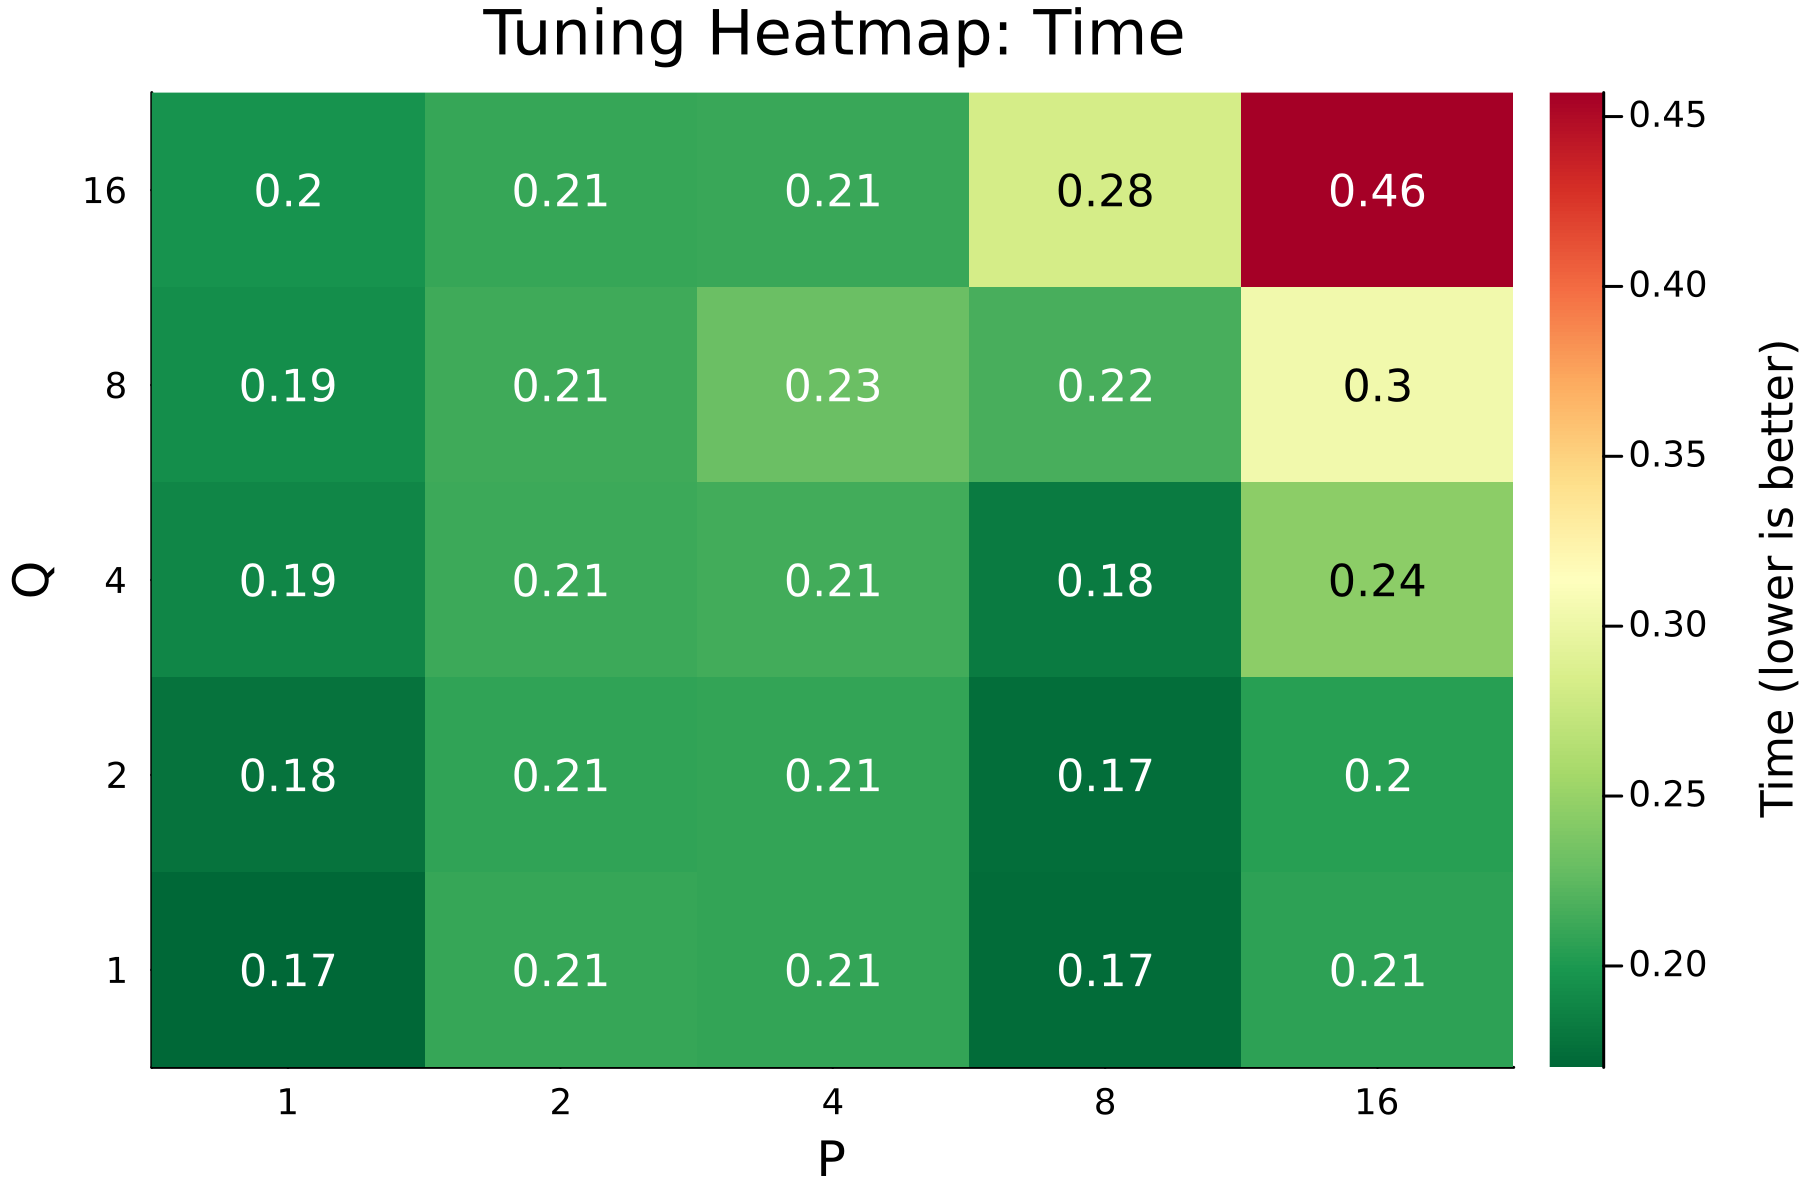

In [16]:
plot_heatmap_tuning_results(results_ti, "P", "Q")

# 3. Expanding the Tuning

## 3.1. Restrictions

To reduce configurations that would not work (either because they can not compile or are always going to be slow), we can use Kernel Tuner's `restriction` setting. This takes a list of strings of expressions. Only configurations that meet all the restriction conditions are left in the searchspace. Let's define a restriction for the product of the block sizes. 

In [17]:
# keep workgroups between one SIMD-group (32) and the hardware maximum (1024 work-items)
restrictions = ["32 <= block_size_x * block_size_y <= 1024"]

1-element Vector{String}:
 "32 <= block_size_x * block_size_y <= 1024"

## 3.2 Optimization Strategies

By default, Kernel Tuner explores ("brute forces") the searchspace. This is often not feasible. As such, Kernel Tuner provides a wide range of optimization strategies, [specified here](https://kerneltuner.github.io/kernel_tuner/stable/optimization.html#optimization-strategies). 

In [18]:
strategy = "genetic_algorithm"
# strategy = "dual_annealing"
# strategy = "random_sample"
# strategy = "bayes_opt"

"genetic_algorithm"

# 3.3. Limits

In addition, we can introduce a limit on the number of evaluations or the time taken for the tuning. This means that Kernel Tuner will stop searching after this limit is hit and return the best configuration found so far. This is set with the keys `time_limit` (in seconds) or `max_feval`, along with any additional strategy-specific options, in a list of tuples passed to `strategy_options`. 

In [19]:
# strategy_options=[("max_fevals", 100)]
strategy_options=[("time_limit", 30)]

1-element Vector{Tuple{String, Int64}}:
 ("time_limit", 30)

## 3.4. Caching & Combining It All

The best tile size may depend on the workgroup size and vice versa, so finally we tune both at the same time. Note how much larger the search space becomes. 

Because the searchspace is getting larger, it might be convenient to save the results in a file, which also allows us to pick up where we left in case the tuning is interrupted. We can pass the `cache` argument with a filename of our choice. While tuning, the cache file grows one configuration at a time; the helper `with_live_tuning_plot` (defined in the setup) reads it in the background and keeps a scatterplot of the results so far up to date. If you run the cell again after execution, you'll notice it now immediately pulls all results from the cachefile.

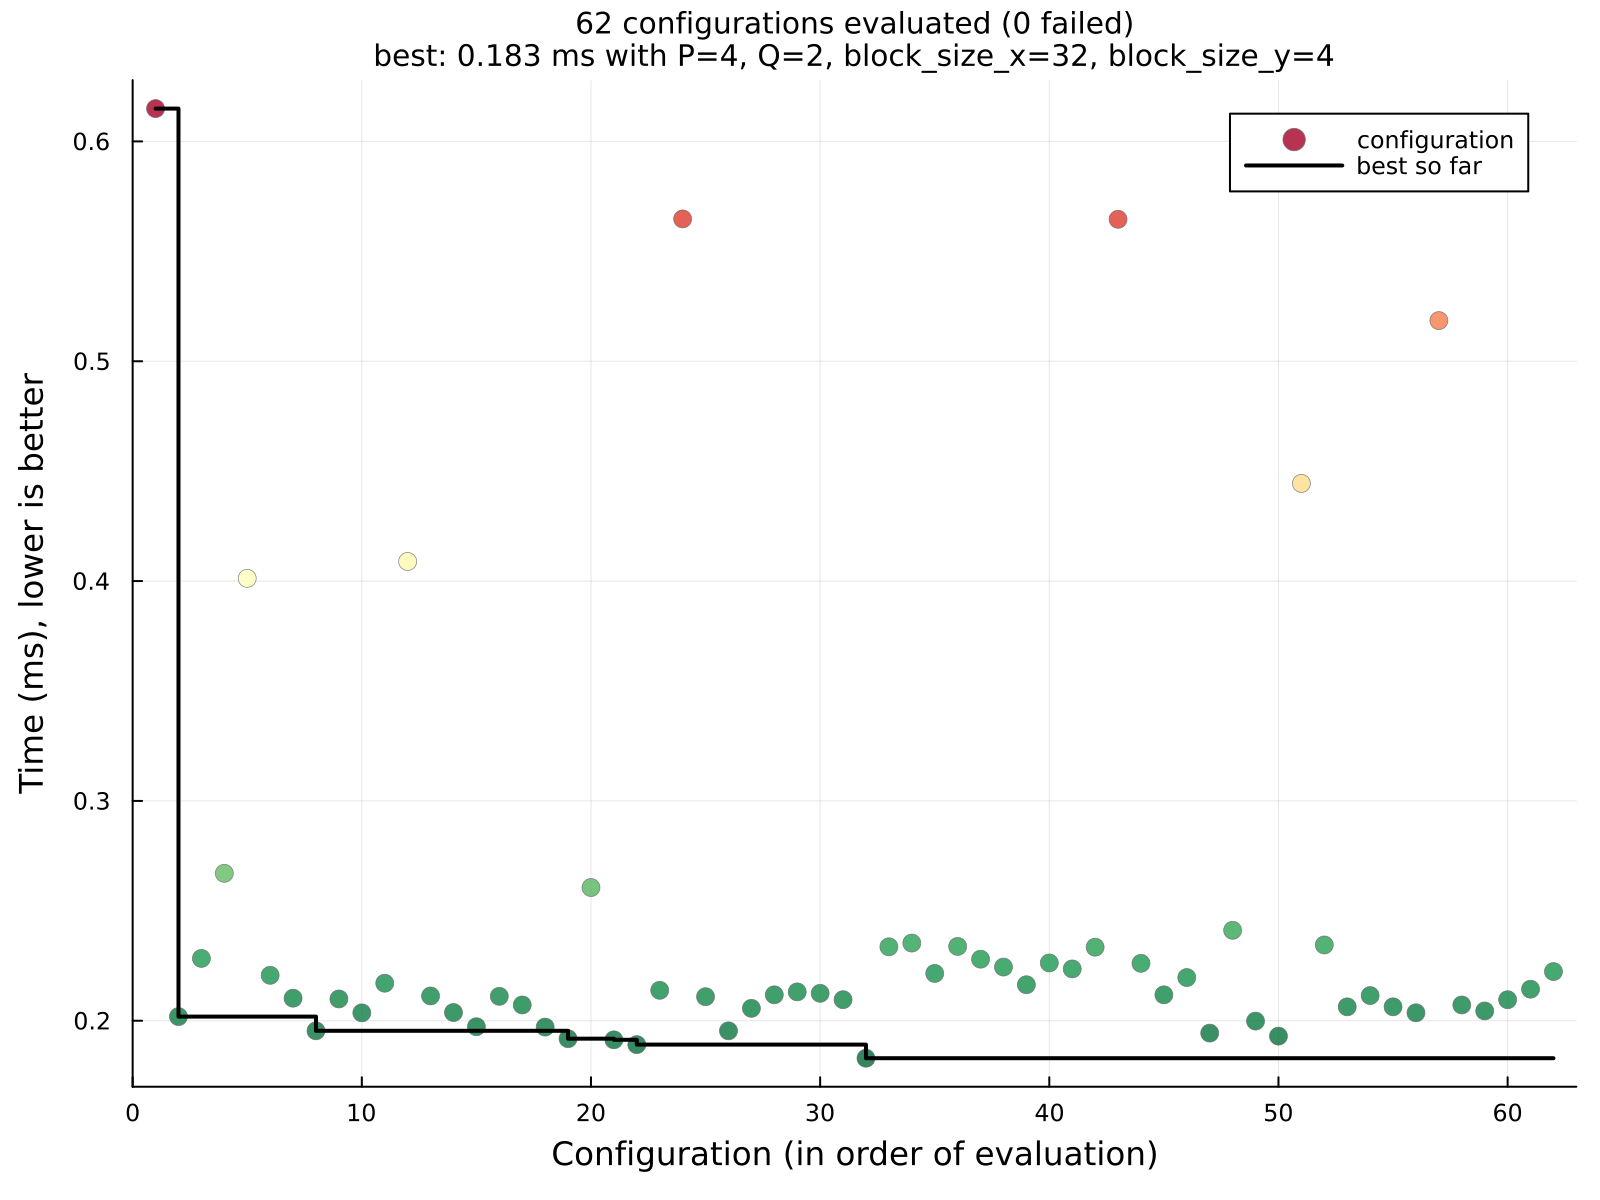

Using: NVIDIA RTX A6000
Searchspace has 525 configurations after restrictions.
P=4, Q=8, block_size_x=128, block_size_y=1, time=0.234ms
P=4, Q=4, block_size_x=64, block_size_y=16, time=0.235ms
P=2, Q=8, block_size_x=32, block_size_y=16, time=0.222ms
P=2, Q=1, block_size_x=64, block_size_y=2, time=0.234ms
P=4, Q=4, block_size_x=32, block_size_y=8, time=0.228ms
P=1, Q=1, block_size_x=32, block_size_y=2, time=0.224ms
P=8, Q=1, block_size_x=32, block_size_y=4, time=0.216ms
P=2, Q=4, block_size_x=8, block_size_y=4, time=0.226ms
P=4, Q=4, block_size_x=16, block_size_y=16, time=0.224ms
P=1, Q=2, block_size_x=16, block_size_y=2, time=0.233ms
P=16, Q=16, block_size_x=16, block_size_y=16, time=0.565ms
P=1, Q=16, block_size_x=128, block_size_y=1, time=0.226ms
P=16, Q=2, block_size_x=8, block_size_y=8, time=0.212ms
P=16, Q=2, block_size_x=64, block_size_y=16, time=0.220ms
P=4, Q=1, block_size_x=32, block_size_y=2, time=0.194ms
P=16, Q=4, block_size_x=8, block_size_y=4, time=0.241ms
P=16, Q=2, bloc

(Dict{String, Any}[Dict("compile_time" => 27.157607953995466, "Q" => 8, "time" => 0.23364266477680454, "P" => 4, "times" => [0.3809280169662088, 0.2467840095050633, 0.22732799698133022, 0.24371199833694845, 0.2222079929197207, 0.2344959939364344, 0.22732799698133022], "verification_time" => 0, "benchmark_time" => 905.6711890734732, "framework_time" => 62.02331783617701, "block_size_x" => 128, "block_size_y" => 1…), Dict("compile_time" => 27.591939084231853, "Q" => 4, "time" => 0.23533866139284024, "P" => 4, "times" => [0.24371199833694845, 0.23142399732023478, 0.24883198784664273, 0.2344959939364344, 0.22015998547431082, 0.24979200679808855, 0.22732799698133022], "verification_time" => 0, "benchmark_time" => 994.789230171591, "framework_time" => 62.02331783617701, "block_size_x" => 64, "block_size_y" => 16…), Dict("compile_time" => 30.06940009072423, "Q" => 8, "time" => 0.22153066674945876, "P" => 2, "times" => [0.2529280027374625, 0.22742399596609175, 0.21196799934841692, 0.2293760044

In [20]:
using KernelTuner

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]
tune_params = [
    ("P", [1, 2, 4, 8, 16]),                    # tile size per work-item along y
    ("Q", [1, 2, 4, 8, 16]),                    # tile size per work-item along x
    ("block_size_x", [8, 16, 32, 64, 128]),     # workgroup size along x
    ("block_size_y", [1, 2, 4, 8, 16]),         # workgroup size along y
]

cachefile = "gs_gpu_kernel_tuned.json"

# the plot above the tuning output is redrawn as configurations are added to the cache file (Kernel Tuner appends ".json")
results_wg_ti, env = with_live_tuning_plot(cachefile) do
    KernelTuner.tune_kernel(
        "gs_gpu_kernel_tiled!",
        get_cell_by_tag("gs_gpu_kernel_tiled"), # we're getting the kernel source code from of this notebook, but normally you would just pass either the string or the filename
        (n, n),
        arguments,
        tune_params,
        restrictions=restrictions,
        # each workgroup covers (block_size_x * Q) × (block_size_y * P) grid points
        grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
        lang="Julia",
        verbose=true,
        cache=cachefile,
        strategy=strategy,
        strategy_options=strategy_options,
    )
end

# if you'd like to run the cell again without the cached results, uncomment the following line
# rm(cachefile)

# 4. Advanced Tuning Options

Execution time is not the only thing worth tuning for. In this section we look at some more advanced features of Kernel Tuner: checking that every configuration still computes the right result, measuring energy, trading accuracy for speed with mixed precision, and defining your own metrics.

To keep each example quick, we use a smaller search space than in Section 3.

In [21]:
# a smaller search space, so that each example below only takes a few seconds
tune_params_small = [
    ("P", [1, 2, 4]),                   # tile size per work-item along y
    ("Q", [1, 2, 4]),                   # tile size per work-item along x
    ("block_size_x", [32, 64, 128]),    # workgroup size along x
    ("block_size_y", [1, 2, 4]),        # workgroup size along y
]

arguments = [U1, V1, U2, V2, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0]

13-element Vector{Any}:
    CuArray(Float32[0.019 0.095 … 0.03 0.079; 0.016 0.062 … 0.016 0.038; … ; 0.027 0.075 … 0.081 0.048; 0.054 0.077 … 0.011 0.033])
    CuArray(Float32[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])
    CuArray(Float32[0.019 0.095 … 0.03 0.079; 0.016 0.062 … 0.016 0.038; … ; 0.027 0.075 … 0.081 0.048; 0.054 0.077 … 0.011 0.033])
    CuArray(Float32[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])
   0.16f0
   0.08f0
   0.035f0
   0.06f0
   1.0f0
   1.0f0
 500
 500
   0.0f0

## 4.1. Output Verification / Provided Answers

A fast kernel is useless if it computes the wrong result. Tiling makes the indexing more complex, so it is easy to introduce a bug that only shows up for some tile sizes. Kernel Tuner can check the output of every configuration against a reference: pass the expected output with the `answer` argument. This is a list with one entry per kernel argument: the expected array for each output you want to check, and `nothing` for the arguments to skip.

As reference, we run one step of the simple kernel `gs_gpu_kernel!` on the CPU. Thanks to KernelAbstractions, this is the same kernel code, just launched on a different backend. The reference output arrays start as copies of the input, just like `U1` and `V1`, because the kernel does not write the boundary cells.

In [22]:
# reference output: one step of the simple kernel, run on the CPU
U_ref, V_ref = copy(U), copy(V)
gs_gpu_kernel!(CPU(), (16, 16))(U_ref, V_ref, U, V, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0, ndrange=(n, n))

# one entry per kernel argument: check Uout and Vout, skip the rest
answer = [U_ref, V_ref, fill(nothing, length(arguments) - 2)...]

results_verified, _ = KernelTuner.tune_kernel(
    "gs_gpu_kernel_tiled!",
    get_cell_by_tag("gs_gpu_kernel_tiled"),
    (n, n),
    arguments,
    tune_params_small,
    restrictions=restrictions,
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia",
    answer=answer,
    atol=1e-5,  # maximum absolute difference allowed, the GPU and CPU may round slightly differently
    verbose=true,
)

println("All $(length(results_verified)) configurations computed the correct result.")

Using: NVIDIA RTX A6000
Searchspace has 81 configurations after restrictions.
P=1, Q=1, block_size_x=32, block_size_y=1, time=0.165ms
P=1, Q=1, block_size_x=32, block_size_y=2, time=0.170ms
P=1, Q=1, block_size_x=32, block_size_y=4, time=0.171ms
P=1, Q=1, block_size_x=64, block_size_y=1, time=0.170ms
P=1, Q=1, block_size_x=64, block_size_y=2, time=0.173ms
P=1, Q=1, block_size_x=64, block_size_y=4, time=0.176ms
P=1, Q=1, block_size_x=128, block_size_y=1, time=0.173ms
P=1, Q=1, block_size_x=128, block_size_y=2, time=0.173ms
P=1, Q=1, block_size_x=128, block_size_y=4, time=0.175ms
P=1, Q=2, block_size_x=32, block_size_y=1, time=0.180ms
P=1, Q=2, block_size_x=32, block_size_y=2, time=0.183ms
P=1, Q=2, block_size_x=32, block_size_y=4, time=0.181ms
P=1, Q=2, block_size_x=64, block_size_y=1, time=0.185ms
P=1, Q=2, block_size_x=64, block_size_y=2, time=0.194ms
P=1, Q=2, block_size_x=64, block_size_y=4, time=0.194ms
P=1, Q=2, block_size_x=128, block_size_y=1, time=0.198ms
P=1, Q=2, block_size_x

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:84: UserWarning: Measured GPU time 1.203 ms is more than 10x host time 0.098 ms; this may indicate an issue with the timing measurement. Replacing GPU time with host time for this measurement.
  warn(


P=4, Q=2, block_size_x=32, block_size_y=2, time=0.197ms
P=4, Q=2, block_size_x=32, block_size_y=4, time=0.202ms
P=4, Q=2, block_size_x=64, block_size_y=1, time=0.204ms
P=4, Q=2, block_size_x=64, block_size_y=2, time=0.205ms
P=4, Q=2, block_size_x=64, block_size_y=4, time=0.204ms
P=4, Q=2, block_size_x=128, block_size_y=1, time=0.194ms
P=4, Q=2, block_size_x=128, block_size_y=2, time=0.207ms
P=4, Q=2, block_size_x=128, block_size_y=4, time=0.205ms
P=4, Q=4, block_size_x=32, block_size_y=1, time=0.219ms
P=4, Q=4, block_size_x=32, block_size_y=2, time=0.226ms
P=4, Q=4, block_size_x=32, block_size_y=4, time=0.237ms
P=4, Q=4, block_size_x=64, block_size_y=1, time=0.233ms
P=4, Q=4, block_size_x=64, block_size_y=2, time=0.200ms
P=4, Q=4, block_size_x=64, block_size_y=4, time=0.232ms
P=4, Q=4, block_size_x=128, block_size_y=1, time=0.247ms
P=4, Q=4, block_size_x=128, block_size_y=2, time=0.234ms
P=4, Q=4, block_size_x=128, block_size_y=4, time=0.223ms

BEST PERFORMING CONFIGURATION FOR OBJECTI

If a configuration computes a different result, Kernel Tuner stops with an error such as `Kernel result verification failed for: P=1, Q=1, block_size_x=32, block_size_y=1`, so you know exactly which configuration to debug. The default check requires all values to be within `atol` of the answer. For other checks, you can pass your own function with the `verify` argument: `verify(answer, result; atol)` should return `true` or `false`.

## 4.2. Energy Tuning

On many systems, energy is as much a constraint as time. Kernel Tuner measures energy with *observers*: objects that collect extra measurements while a configuration is benchmarked. `KernelTuner.get_energy_observer_for_backend` returns the right observer for your GPU (NVML on NVIDIA, AMD SMI on AMD, `powermetrics` on Apple), together with the names of the quantities it measures.

We pass the observer with `observers`, and set `objective` to the energy so that Kernel Tuner reports the most energy-efficient configuration instead of the fastest one.

<div class="alert alert-info">
  <strong>Apple Silicon</strong><br />Reading the GPU energy with <tt>powermetrics</tt> requires administrator rights. To measure without a password prompt, run <tt>sudo visudo</tt> and add the line <tt>your_username ALL=(ALL) NOPASSWD: /usr/bin/powermetrics</tt>.
</div>

In [23]:
# "default" selects the observer for the first GPU backend that Julia finds
energy_observer, energy_fields = KernelTuner.get_energy_observer_for_backend("default")
energy_key = only(filter(endswith("energy"), energy_fields))   # the name differs per vendor, e.g. "energy" or "nvml_energy"
println("Measuring: ", join(energy_fields, ", "))

results_energy, _ = KernelTuner.tune_kernel(
    "gs_gpu_kernel_tiled!",
    get_cell_by_tag("gs_gpu_kernel_tiled"),
    (n, n),
    arguments,
    tune_params_small,
    restrictions=restrictions,
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia",
    observers=[energy_observer],
    objective=energy_key,   # optimize for energy instead of time
    objective_higher_is_better=true,
    verbose=true,
)

Measuring: power_readings, nvml_power, nvml_energy, core_freq, mem_freq, temperature
Using: NVIDIA RTX A6000
Searchspace has 81 configurations after restrictions.
P=1, Q=1, block_size_x=32, block_size_y=1, time=0.182ms
P=1, Q=1, block_size_x=32, block_size_y=2, time=0.180ms
P=1, Q=1, block_size_x=32, block_size_y=4, time=0.176ms
P=1, Q=1, block_size_x=64, block_size_y=1, time=0.178ms
P=1, Q=1, block_size_x=64, block_size_y=2, time=0.176ms
P=1, Q=1, block_size_x=64, block_size_y=4, time=0.182ms
P=1, Q=1, block_size_x=128, block_size_y=1, time=0.181ms
P=1, Q=1, block_size_x=128, block_size_y=2, time=0.183ms
P=1, Q=1, block_size_x=128, block_size_y=4, time=0.188ms
P=1, Q=2, block_size_x=32, block_size_y=1, time=0.169ms
P=1, Q=2, block_size_x=32, block_size_y=2, time=0.178ms
P=1, Q=2, block_size_x=32, block_size_y=4, time=0.185ms
P=1, Q=2, block_size_x=64, block_size_y=1, time=0.184ms
P=1, Q=2, block_size_x=64, block_size_y=2, time=0.186ms
P=1, Q=2, block_size_x=64, block_size_y=4, time=0.

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:84: UserWarning: Measured GPU time 833.347 ms is more than 10x host time 0.399 ms; this may indicate an issue with the timing measurement. Replacing GPU time with host time for this measurement.
  warn(


P=1, Q=2, block_size_x=128, block_size_y=2, time=0.181ms
P=1, Q=2, block_size_x=128, block_size_y=4, time=0.188ms
P=1, Q=4, block_size_x=32, block_size_y=1, time=0.184ms
P=1, Q=4, block_size_x=32, block_size_y=2, time=0.185ms
P=1, Q=4, block_size_x=32, block_size_y=4, time=0.183ms
P=1, Q=4, block_size_x=64, block_size_y=1, time=0.187ms
P=1, Q=4, block_size_x=64, block_size_y=2, time=0.194ms
P=1, Q=4, block_size_x=64, block_size_y=4, time=0.183ms
P=1, Q=4, block_size_x=128, block_size_y=1, time=0.183ms
P=1, Q=4, block_size_x=128, block_size_y=2, time=0.185ms
P=1, Q=4, block_size_x=128, block_size_y=4, time=0.184ms
P=2, Q=1, block_size_x=32, block_size_y=1, time=0.177ms


/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:84: UserWarning: Measured GPU time 1.754 ms is more than 10x host time 0.128 ms; this may indicate an issue with the timing measurement. Replacing GPU time with host time for this measurement.
  warn(


P=2, Q=1, block_size_x=32, block_size_y=2, time=0.189ms
P=2, Q=1, block_size_x=32, block_size_y=4, time=0.188ms
P=2, Q=1, block_size_x=64, block_size_y=1, time=0.185ms
P=2, Q=1, block_size_x=64, block_size_y=2, time=0.183ms
P=2, Q=1, block_size_x=64, block_size_y=4, time=0.187ms
P=2, Q=1, block_size_x=128, block_size_y=1, time=0.185ms
P=2, Q=1, block_size_x=128, block_size_y=2, time=0.192ms
P=2, Q=1, block_size_x=128, block_size_y=4, time=0.195ms
P=2, Q=2, block_size_x=32, block_size_y=1, time=0.186ms
P=2, Q=2, block_size_x=32, block_size_y=2, time=0.189ms
P=2, Q=2, block_size_x=32, block_size_y=4, time=0.190ms
P=2, Q=2, block_size_x=64, block_size_y=1, time=0.188ms
P=2, Q=2, block_size_x=64, block_size_y=2, time=0.189ms
P=2, Q=2, block_size_x=64, block_size_y=4, time=0.188ms
P=2, Q=2, block_size_x=128, block_size_y=1, time=0.185ms
P=2, Q=2, block_size_x=128, block_size_y=2, time=0.181ms
P=2, Q=2, block_size_x=128, block_size_y=4, time=0.184ms
P=2, Q=4, block_size_x=32, block_size_y=1,

(Dict{String, Any}[Dict("compile_time" => 18.47961824387312, "Q" => 1, "time" => 0.181749334539442, "P" => 1, "times" => [0.1904640084831044, 0.18739199731498957, 0.19251200137659907, 0.17504001152701676, 0.17817600746639073, 0.1812479895306751, 0.17612800002098083], "core_freq" => 1800.0, "temperature" => 34.0, "nvml_energy" => 0.01179116982758084, "verification_time" => 0, "benchmark_time" => 1479.9071601592004…), Dict("compile_time" => 18.10229290276766, "Q" => 1, "time" => 0.17971199849853292, "P" => 1, "times" => [0.20787199900951236, 0.18943999020848423, 0.17919999663718045, 0.1822720078052953, 0.17100801051128656, 0.17715198919177055, 0.17919999663718045], "core_freq" => 1800.0, "temperature" => 35.0, "nvml_energy" => 0.011649111454673402, "verification_time" => 0, "benchmark_time" => 1547.6136030629277…), Dict("compile_time" => 18.27602693811059, "Q" => 1, "time" => 0.17628800317955515, "P" => 1, "times" => [0.1842560013756156, 0.18636800814419985, 0.17606400069780648, 0.179199

Let's compare the time and energy of each configuration, and see whether the fastest configuration is also the most energy-efficient one:

Fastest:       P=1, Q=2, block_size_x=32, block_size_y=1  (0.169 ms, 0.0169 J)
Lowest energy: P=1, Q=1, block_size_x=64, block_size_y=2  (0.176 ms, 0.0114 J)


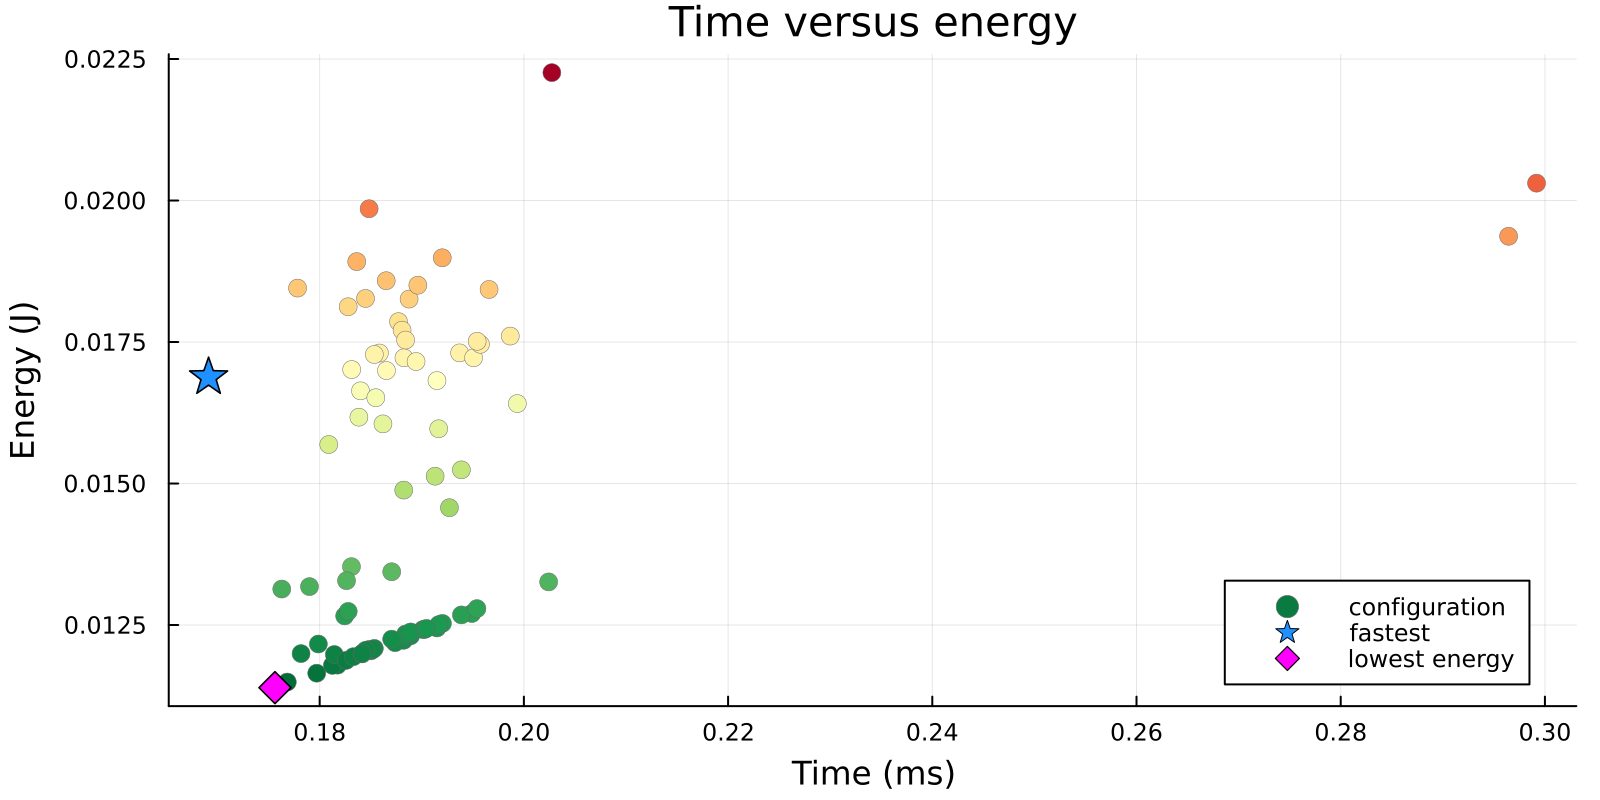

In [24]:
config_string(r) = join(["$k=$(r[k])" for k in first.(tune_params_small)], ", ")

times = [r["time"] for r in results_energy]
energies = [r[energy_key] for r in results_energy]
fastest, most_efficient = argmin(times), argmin(energies)
println("Fastest:       ", config_string(results_energy[fastest]), "  ($(round(times[fastest], digits=3)) ms, $(round(energies[fastest], sigdigits=3)) J)")
println("Lowest energy: ", config_string(results_energy[most_efficient]), "  ($(round(times[most_efficient], digits=3)) ms, $(round(energies[most_efficient], sigdigits=3)) J)")

scatter(times, energies; label="configuration", marker_z=energies, color=reverse(cgrad(:RdYlGn)), colorbar=false,
    markersize=5, markerstrokewidth=0.3, markerstrokecolor=:gray40,
    xlabel="Time (ms)", ylabel="Energy (J)", title="Time versus energy", size=(800, 400), dpi=200,
    left_margin=3Plots.mm, bottom_margin=3Plots.mm)
scatter!([times[fastest]], [energies[fastest]]; marker=:star5, markersize=10, color=:dodgerblue, label="fastest")
scatter!([times[most_efficient]], [energies[most_efficient]]; marker=:diamond, markersize=8, color=:magenta, label="lowest energy")

Time and energy are related, as a kernel that finishes sooner draws power for a shorter time. But they are not the same: a configuration that keeps the GPU less busy can be slightly slower, yet draw less power. Keep in mind that energy is measured with a coarser resolution than time, especially for short kernels like this one, so expect some noise in these measurements.

## 4.3. Accuracy Tuning & Mixed Precision

So far, every configuration had to produce (nearly) the same result. Sometimes, a less accurate result is acceptable if it is computed faster. A common example is *mixed precision*: storing data or doing arithmetic in 16-bit instead of 32-bit floating point halves the memory traffic and can use faster hardware, at the cost of accuracy.

We make a variant of the simple kernel with two extra tunable parameters: `storage_bits`, the precision of the arrays, and `compute_bits`, the precision of the arithmetic. Julia kernels are generic, so the kernel works for any array type; the compute type `T` is chosen from the `COMPUTE_BITS` parameter, and values are converted to `T` before any arithmetic.

In [25]:
using KernelAbstractions

# 5-point Laplacian like before, but with the values converted to the compute type `T` before the arithmetic
@inline function laplacian_T(::Type{T}, A, x, y, dx) where {T}
    @inbounds c = T(A[x, y])
    @inbounds DAx = (T(A[x-1, y]) - 2 * c + T(A[x+1, y])) / T(dx)
    @inbounds DAy = (T(A[x, y-1]) - 2 * c + T(A[x, y+1])) / T(dx)
    return DAx + DAy
end

# Same computation as `gs_gpu_kernel!`, with two extra tunable parameters:
# STORAGE_BITS is the precision of the arrays (Kernel Tuner passes the matching arrays, see below), COMPUTE_BITS the precision of the arithmetic.
@kernel function gs_gpu_kernel_mixed!(Uout, Vout, @Const(U), @Const(V), D_u, D_v, F, k, dt, dx, nx, ny, noise,
        ::Val{BX}, ::Val{BY}, ::Val{STORAGE_BITS}, ::Val{COMPUTE_BITS}) where {BX, BY, STORAGE_BITS, COMPUTE_BITS}
    T = COMPUTE_BITS == 16 ? Float16 : Float32
    x, y = @index(Global, NTuple)

    if (1 < x < nx) && (1 < y < ny)
        u = @inbounds T(U[x, y])
        v = @inbounds T(V[x, y])

        ΔU = laplacian_T(T, U, x, y, dx)
        ΔV = laplacian_T(T, V, x, y, dx)
        UVV = u * v * v
        DU = T(D_u) * ΔU - UVV + T(F) * (1 - u)
        DV = T(D_v) * ΔV + UVV - (T(F) + T(k)) * v

        @inbounds Uout[x, y] = u + DU * T(dt)   # converted to the storage type on write
        @inbounds Vout[x, y] = v + DV * T(dt)
    end
end

gs_gpu_kernel_mixed! (generic function with 4 methods)

Depending on `storage_bits`, Kernel Tuner must pass either the 32-bit or the 16-bit arrays to the kernel. For this we use `KernelTuner.Tunable(param, Dict(value => array))`: for each configuration, Kernel Tuner selects the array that matches the value of the parameter.

As reference, we compute the answer in 64-bit precision on the CPU. We use a larger grid here, because the differences in memory traffic become more visible on larger problems.

In [26]:
n_mixed = 2048
U_mixed = Float32.(rand(0.0:0.001:0.1, n_mixed, n_mixed))
V_mixed = zeros(Float32, n_mixed, n_mixed)
mid = div(n_mixed, 2)
U_mixed[mid-5:mid+5, mid-5:mid+5] .= Float32(1.0 * init_multi)
V_mixed[mid-5:mid+5, mid-5:mid+5] .= Float32(0.5 * init_multi)

# reference output in 64-bit precision, computed on the CPU
U_ref64, V_ref64 = Float64.(U_mixed), Float64.(V_mixed)
gs_gpu_kernel!(CPU(), (16, 16))(U_ref64, V_ref64, Float64.(U_mixed), Float64.(V_mixed),
    0.16, 0.08, 0.035, 0.06, 1.0, 1.0, n_mixed, n_mixed, 0.0, ndrange=(n_mixed, n_mixed))

# every array argument is selected by the value of `storage_bits`
storage(A) = KernelTuner.Tunable("storage_bits", Dict(32 => Float32.(A), 16 => Float16.(A)))
arguments_mixed = [storage(U_mixed), storage(V_mixed), storage(U_mixed), storage(V_mixed),
                   0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n_mixed, n_mixed, 0.0f0]

13-element Vector{Any}:
     <py {32: Julia:
2048×2048 Matrix{Float32}:
 0.071  0.07   0.075  0.002  0.01   …  0.069  0.076  0.065  0.026  0.002
 0.028  0.033  0.049  0.032  0.04      0.048  0.099  0.015  0.005  0.036
 0.083  0.048  0.058  0.022  0.004     0.052  0.052  0.055  0.041  0.082
 0.024  0.086  0.088  0.015  0.073     0.098  0.015  0.056  0.069  0.086
 0.053  0.07   0.065  0.03   0.049     0.09   0.084  0.077  0.071  0.026
 0.028  0.021  0.006  0.071  0.037  …  0.004  0.023  0.037  0.065  0.037
 0.024  0.049  0.056  0.076  0.097     0.035  0.04   0.049  0.095  0.066
 0.044  0.001  0.039  0.044  0.042     0.039  0.006  0.053  0.087  0.05
 0.008  0.029  0.073  0.047  0.038     0.071  0.049  0.005  0.1    0.065
 ⋮                                  ⋱                ⋮             
 0.099  0.067  0.092  0.022  0.046     0.084  0.021  0.099  0.022  0.028
 0.071  0.068  0.031  0.031  0.062  …  0.083  0.017  0.003  0.05   0.075
 0.023  0.093  0.089  0.066  0.092     0.091  0.04   0.029

To measure the accuracy, we add an `AccuracyObserver`. It compares the outputs of each configuration to the `answer` and adds the error, here the root-mean-square error (RMSE), to the results as `error`. Instead of a name such as `"RMSE"`, `"MAE"` or `"relative error"`, you can also pass your own Julia function `(answer, output) -> error`. With an accuracy observer, configurations whose output deviates from the answer are no longer rejected as in Section 4.1: instead, the deviation is measured.

In [27]:
tune_params_mixed = [
    # ("block_size_x", [32, 64, 128]),
    # ("block_size_y", [1, 2, 4]),
    ("block_size_x", [8, 16, 32, 64, 128]),  # workgroup size along x
    ("block_size_y", [1, 2, 4, 8, 16]),      # workgroup size along y
    ("storage_bits", [32, 16]),     # precision of the arrays
    ("compute_bits", [32, 16]),     # precision of the arithmetic
]

accuracy_observer = AccuracyObserver("RMSE")   # or your own function, e.g. AccuracyObserver((answer, output) -> maximum(abs.(answer .- output)))

results_mixed, _ = KernelTuner.tune_kernel(
    "gs_gpu_kernel_mixed!",
    get_cell_by_tag("gs_gpu_kernel_mixed"),
    (n_mixed, n_mixed),
    arguments_mixed,
    tune_params_mixed,
    restrictions=restrictions,
    lang="Julia",
    answer=[U_ref64, V_ref64, fill(nothing, length(arguments_mixed) - 2)...],
    observers=[accuracy_observer],
    verbose=true,
)

Using: NVIDIA RTX A6000
Searchspace has 84 configurations after restrictions.
block_size_x=8, block_size_y=4, storage_bits=32, compute_bits=32, time=0.258ms
block_size_x=8, block_size_y=4, storage_bits=32, compute_bits=16, time=0.264ms
block_size_x=8, block_size_y=4, storage_bits=16, compute_bits=32, time=0.255ms
block_size_x=8, block_size_y=4, storage_bits=16, compute_bits=16, time=0.256ms
block_size_x=8, block_size_y=8, storage_bits=32, compute_bits=32, time=0.202ms
block_size_x=8, block_size_y=8, storage_bits=32, compute_bits=16, time=0.202ms
block_size_x=8, block_size_y=8, storage_bits=16, compute_bits=32, time=0.189ms
block_size_x=8, block_size_y=8, storage_bits=16, compute_bits=16, time=0.190ms
block_size_x=8, block_size_y=16, storage_bits=32, compute_bits=32, time=0.198ms
block_size_x=8, block_size_y=16, storage_bits=32, compute_bits=16, time=0.199ms
block_size_x=8, block_size_y=16, storage_bits=16, compute_bits=32, time=0.170ms
block_size_x=8, block_size_y=16, storage_bits=16, 

(Dict{String, Any}[Dict("compile_time" => 9.391361847519875, "compute_bits" => 32, "time" => 0.25753600251240033, "times" => [0.2600960142444819, 0.26112000341527164, 0.2549760101828724, 0.258048006799072, 0.2549760101828724, 0.25702398852445185, 0.25907199596986175], "verification_time" => 689.0808138996363, "benchmark_time" => 3.261735662817955, "framework_time" => 27.584912018127905, "error" => 2.7959035307188307e-9, "storage_bits" => 32, "block_size_x" => 8…), Dict("compile_time" => 13.94187705591321, "compute_bits" => 16, "time" => 0.2635146665852517, "times" => [0.2693760034162551, 0.27136001153849065, 0.26214399258606136, 0.26624000747688115, 0.2611519885249436, 0.26112000341527164, 0.25907199596986175], "verification_time" => 689.8710308596492, "benchmark_time" => 3.327269107103348, "framework_time" => 27.584912018127905, "error" => 2.379666612456674e-5, "storage_bits" => 32, "block_size_x" => 8…), Dict("compile_time" => 13.950604014098644, "compute_bits" => 32, "time" => 0.254

Now we can choose the fastest configuration whose error stays within a tolerance of our choice:

Fastest overall:                block_size_x=32, block_size_y=4, storage_bits=16, compute_bits=32  (0.164 ms, error 1.81e-5)
Fastest with error ≤ 1.0e-6:    block_size_x=128, block_size_y=2, storage_bits=32, compute_bits=32  (0.197 ms, error 2.8e-9)


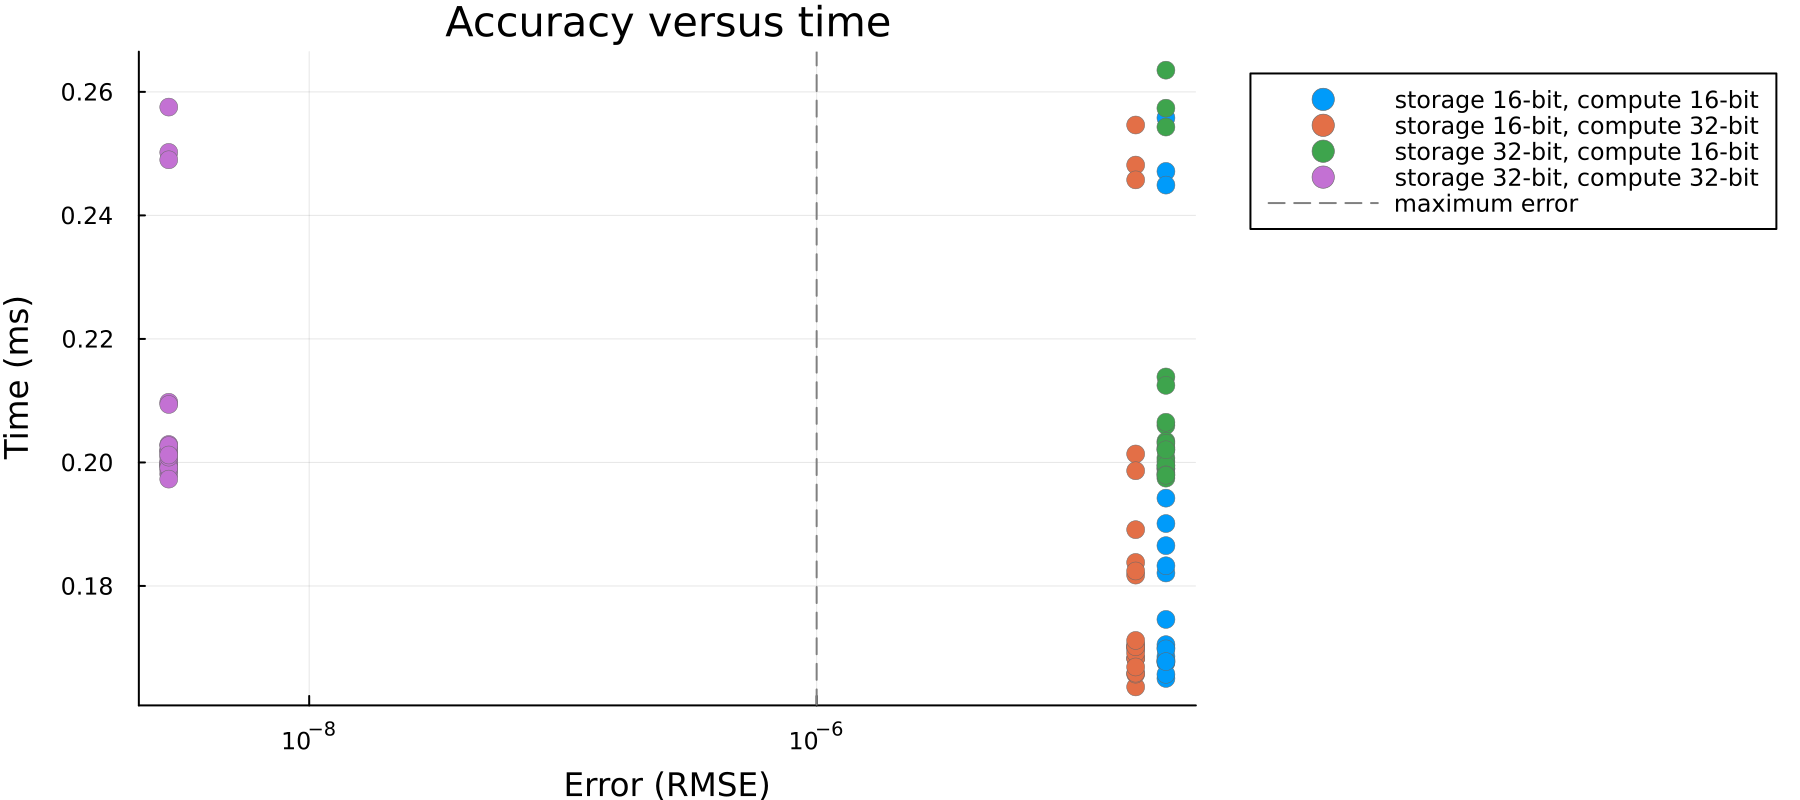

In [28]:
max_error = 1e-6
precision_label(r) = "storage $(r["storage_bits"])-bit, compute $(r["compute_bits"])-bit"
config_string_mixed(r) = join(["$k=$(r[k])" for k in first.(tune_params_mixed)], ", ")

fastest_overall = argmin(r -> r["time"], results_mixed)
fastest_accurate = argmin(r -> r["time"], filter(r -> r["error"] <= max_error, results_mixed))
for (name, r) in [("Fastest overall", fastest_overall), ("Fastest with error ≤ $max_error", fastest_accurate)]
    println(rpad(name * ":", 32), config_string_mixed(r), "  ($(round(r["time"], digits=3)) ms, error $(round(r["error"], sigdigits=3)))")
end

scatter([r["error"] for r in results_mixed], [r["time"] for r in results_mixed]; group=precision_label.(results_mixed),
    markersize=5, markerstrokewidth=0.3, markerstrokecolor=:gray40, xscale=:log10,
    xlabel="Error (RMSE)", ylabel="Time (ms)", title="Accuracy versus time", legend=:outertopright,
    size=(900, 400), dpi=200, left_margin=3Plots.mm, bottom_margin=3Plots.mm)
vline!([max_error]; linestyle=:dash, color=:gray, label="maximum error")

The configurations are grouped by precision: with 32-bit storage and arithmetic, the result is almost exact, while 16-bit storage or arithmetic increases the error by several orders of magnitude. Whether the 16-bit configurations are also faster depends on your GPU and on how memory-bound the kernel is. Whether the extra error is acceptable depends on your application, which is why we choose the fastest configuration within a tolerance. Keep in mind that this is the error of a single time step: over a full simulation, errors accumulate.

## 4.4. User-Defined Metrics

Execution time alone does not tell you how close a kernel comes to the capabilities of the hardware. With `metrics`, Kernel Tuner computes derived quantities for every configuration, such as the achieved computational throughput (GFLOP/s) and memory bandwidth (GB/s). A metric is either a string with an expression, in which the tunable parameters and measured results such as `time` (in milliseconds) can be used, or a Julia function that receives the parameters and results of a configuration as a `Dict`. Metrics are evaluated in order and can use earlier metrics, so we pass them as a vector of `name => metric` pairs, which keeps that order.

For each grid point, the kernel performs about 34 floating-point operations, and at the very least reads `U` and `V` and writes `Uout` and `Vout` once: 4 × 4 bytes. Any metric can also be used as the `objective`, here we maximize the bandwidth.

In [29]:
flops_per_point = 34                    # floating-point operations per grid point, counted from the kernel
bytes_per_point = 4 * sizeof(Float32)   # read U and V, write Uout and Vout
grid_points = (n - 2)^2                 # the boundary is not updated

metrics = [
    "GFLOP/s" => "$(flops_per_point * grid_points / 1e9) / (time / 1e3)",   # time is in milliseconds
    "GB/s" => "$(bytes_per_point * grid_points / 1e9) / (time / 1e3)",
    "work-items" => p -> p["block_size_x"] * p["block_size_y"],            # a Julia function works too
]

tune_params_medium = [
    ("P", [1, 2, 4, 8]),                        # tile size per work-item along y
    ("Q", [1, 2, 4, 8]),                        # tile size per work-item along x
    ("block_size_x", [8, 16, 32, 64, 128]),     # workgroup size along x
    ("block_size_y", [1, 2, 4, 8, 16]),         # workgroup size along y
]

results_metrics, env_metrics = KernelTuner.tune_kernel(
    "gs_gpu_kernel_tiled!",
    get_cell_by_tag("gs_gpu_kernel_tiled"),
    (n, n),
    arguments,
    tune_params_medium,
    restrictions=restrictions,
    grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
    lang="Julia",
    metrics=metrics,
    objective="GB/s",               # any metric can be the objective
    objective_higher_is_better=true,
    verbose=true,
)

Using: NVIDIA RTX A6000
Searchspace has 336 configurations after restrictions.
P=1, Q=1, block_size_x=8, block_size_y=4, time=0.178ms, GFLOP/s=47.366, GB/s=22.290, work-items=32
P=1, Q=1, block_size_x=8, block_size_y=8, time=0.181ms, GFLOP/s=46.654, GB/s=21.955, work-items=64
P=1, Q=1, block_size_x=8, block_size_y=16, time=0.182ms, GFLOP/s=46.263, GB/s=21.771, work-items=128
P=1, Q=1, block_size_x=16, block_size_y=2, time=0.183ms, GFLOP/s=46.175, GB/s=21.729, work-items=32
P=1, Q=1, block_size_x=16, block_size_y=4, time=0.183ms, GFLOP/s=45.960, GB/s=21.628, work-items=64
P=1, Q=1, block_size_x=16, block_size_y=8, time=0.185ms, GFLOP/s=45.580, GB/s=21.449, work-items=128
P=1, Q=1, block_size_x=16, block_size_y=16, time=0.185ms, GFLOP/s=45.578, GB/s=21.449, work-items=256
P=1, Q=1, block_size_x=32, block_size_y=1, time=0.192ms, GFLOP/s=43.839, GB/s=20.630, work-items=32
P=1, Q=1, block_size_x=32, block_size_y=2, time=0.193ms, GFLOP/s=43.651, GB/s=20.541, work-items=64
P=1, Q=1, block_siz

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:95: UserWarning: Measured GPU time 1.540 ms is substantially greater than host time 0.157 ms; this may indicate an issue with the timing measurement.
  warn(


P=2, Q=2, block_size_x=32, block_size_y=4, time=0.250ms, GFLOP/s=33.702, GB/s=15.860, work-items=128
P=2, Q=2, block_size_x=32, block_size_y=8, time=0.238ms, GFLOP/s=35.396, GB/s=16.657, work-items=256
P=2, Q=2, block_size_x=32, block_size_y=16, time=0.229ms, GFLOP/s=36.843, GB/s=17.338, work-items=512
P=2, Q=2, block_size_x=64, block_size_y=1, time=0.241ms, GFLOP/s=35.040, GB/s=16.490, work-items=64
P=2, Q=2, block_size_x=64, block_size_y=2, time=0.234ms, GFLOP/s=35.982, GB/s=16.933, work-items=128
P=2, Q=2, block_size_x=64, block_size_y=4, time=0.244ms, GFLOP/s=34.574, GB/s=16.270, work-items=256
P=2, Q=2, block_size_x=64, block_size_y=8, time=0.261ms, GFLOP/s=32.271, GB/s=15.186, work-items=512
P=2, Q=2, block_size_x=64, block_size_y=16, time=0.239ms, GFLOP/s=35.266, GB/s=16.596, work-items=1024
P=2, Q=2, block_size_x=128, block_size_y=1, time=0.232ms, GFLOP/s=36.302, GB/s=17.083, work-items=128
P=2, Q=2, block_size_x=128, block_size_y=2, time=0.249ms, GFLOP/s=33.842, GB/s=15.926, w

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:95: UserWarning: Measured GPU time 1.450 ms is substantially greater than host time 0.147 ms; this may indicate an issue with the timing measurement.
  warn(


P=2, Q=4, block_size_x=16, block_size_y=8, time=0.209ms, GFLOP/s=40.264, GB/s=18.948, work-items=128
P=2, Q=4, block_size_x=16, block_size_y=16, time=0.222ms, GFLOP/s=37.948, GB/s=17.858, work-items=256
P=2, Q=4, block_size_x=32, block_size_y=1, time=0.222ms, GFLOP/s=37.916, GB/s=17.843, work-items=32
P=2, Q=4, block_size_x=32, block_size_y=2, time=0.241ms, GFLOP/s=34.941, GB/s=16.443, work-items=64
P=2, Q=4, block_size_x=32, block_size_y=4, time=0.230ms, GFLOP/s=36.626, GB/s=17.236, work-items=128
P=2, Q=4, block_size_x=32, block_size_y=8, time=0.200ms, GFLOP/s=42.231, GB/s=19.873, work-items=256
P=2, Q=4, block_size_x=32, block_size_y=16, time=0.197ms, GFLOP/s=42.703, GB/s=20.095, work-items=512
P=2, Q=4, block_size_x=64, block_size_y=1, time=0.209ms, GFLOP/s=40.369, GB/s=18.997, work-items=64
P=2, Q=4, block_size_x=64, block_size_y=2, time=0.225ms, GFLOP/s=37.401, GB/s=17.601, work-items=128
P=2, Q=4, block_size_x=64, block_size_y=4, time=0.237ms, GFLOP/s=35.596, GB/s=16.751, work-i

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:84: UserWarning: Measured GPU time 1.565 ms is more than 10x host time 0.118 ms; this may indicate an issue with the timing measurement. Replacing GPU time with host time for this measurement.
  warn(


... (2 outputs left out)

P=4, Q=2, block_size_x=32, block_size_y=8, time=0.223ms, GFLOP/s=37.830, GB/s=17.802, work-items=256
P=4, Q=2, block_size_x=32, block_size_y=16, time=0.211ms, GFLOP/s=39.879, GB/s=18.766, work-items=512
P=4, Q=2, block_size_x=64, block_size_y=1, time=0.222ms, GFLOP/s=37.976, GB/s=17.871, work-items=64
P=4, Q=2, block_size_x=64, block_size_y=2, time=0.222ms, GFLOP/s=37.973, GB/s=17.870, work-items=128
P=4, Q=2, block_size_x=64, block_size_y=4, time=0.239ms, GFLOP/s=35.241, GB/s=16.584, work-items=256
P=4, Q=2, block_size_x=64, block_size_y=8, time=0.227ms, GFLOP/s=37.176, GB/s=17.495, work-items=512
P=4, Q=2, block_size_x=64, block_size_y=16, time=0.214ms, GFLOP/s=39.332, GB/s=18.509, work-items=1024
P=4, Q=2, block_size_x=128, block_size_y=1, time=0.216ms, GFLOP/s=39.085, GB/s=18.393, work-items=128
P=4, Q=2, block_size_x=128, block_size_y=2, time=0.225ms, GFLOP/s=37.431, GB/s=17.615, work-items=256
P=4, Q=2, block_size_x=128, block_size_y=4, time=0.236ms, GFLOP/s=35.750, GB/s=16.824, 

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:84: UserWarning: Measured GPU time 1.334 ms is more than 10x host time 0.098 ms; this may indicate an issue with the timing measurement. Replacing GPU time with host time for this measurement.
  warn(


P=4, Q=8, block_size_x=128, block_size_y=4, time=0.203ms, GFLOP/s=41.522, GB/s=19.540, work-items=512
P=4, Q=8, block_size_x=128, block_size_y=8, time=0.215ms, GFLOP/s=39.307, GB/s=18.497, work-items=1024
P=8, Q=1, block_size_x=8, block_size_y=4, time=0.236ms, GFLOP/s=35.726, GB/s=16.812, work-items=32
P=8, Q=1, block_size_x=8, block_size_y=8, time=0.253ms, GFLOP/s=33.294, GB/s=15.668, work-items=64
P=8, Q=1, block_size_x=8, block_size_y=16, time=0.259ms, GFLOP/s=32.543, GB/s=15.315, work-items=128
P=8, Q=1, block_size_x=16, block_size_y=2, time=0.245ms, GFLOP/s=34.432, GB/s=16.203, work-items=32
P=8, Q=1, block_size_x=16, block_size_y=4, time=0.250ms, GFLOP/s=33.703, GB/s=15.860, work-items=64
P=8, Q=1, block_size_x=16, block_size_y=8, time=0.252ms, GFLOP/s=33.497, GB/s=15.763, work-items=128
P=8, Q=1, block_size_x=16, block_size_y=16, time=0.247ms, GFLOP/s=34.119, GB/s=16.056, work-items=256
P=8, Q=1, block_size_x=32, block_size_y=1, time=0.250ms, GFLOP/s=33.771, GB/s=15.892, work-it

(Dict{String, Any}[Dict("compile_time" => 20.295683294534683, "Q" => 1, "time" => 0.17802133030879, "P" => 1, "times" => [0.1812479895306751, 0.18636800814419985, 0.18131198885384947, 0.18012798682320863, 0.1761919993441552, 0.17209599900525063, 0.17203199968207628], "GFLOP/s" => 47.36587455769425, "verification_time" => 0, "benchmark_time" => 622.7270499803126, "framework_time" => 6.516451183079837, "block_size_x" => 8…), Dict("compile_time" => 20.917855203151703, "Q" => 1, "time" => 0.18073600464655706, "P" => 1, "times" => [0.20172800577711314, 0.1884160010376945, 0.18220800848212093, 0.17203199968207628, 0.18848000036086887, 0.17817600746639073, 0.17510401085019112], "GFLOP/s" => 46.654433998857506, "verification_time" => 0, "benchmark_time" => 668.8057607971132, "framework_time" => 6.516451183079837, "block_size_x" => 8…), Dict("compile_time" => 20.927282981574535, "Q" => 1, "time" => 0.18226666967772567, "P" => 1, "times" => [0.18524800543673337, 0.18230399291496724, 0.1853760040

The heatmap function from the setup also accepts any metric. Let's look at the achieved bandwidth for the tile sizes, using the workgroup size of the best configuration:

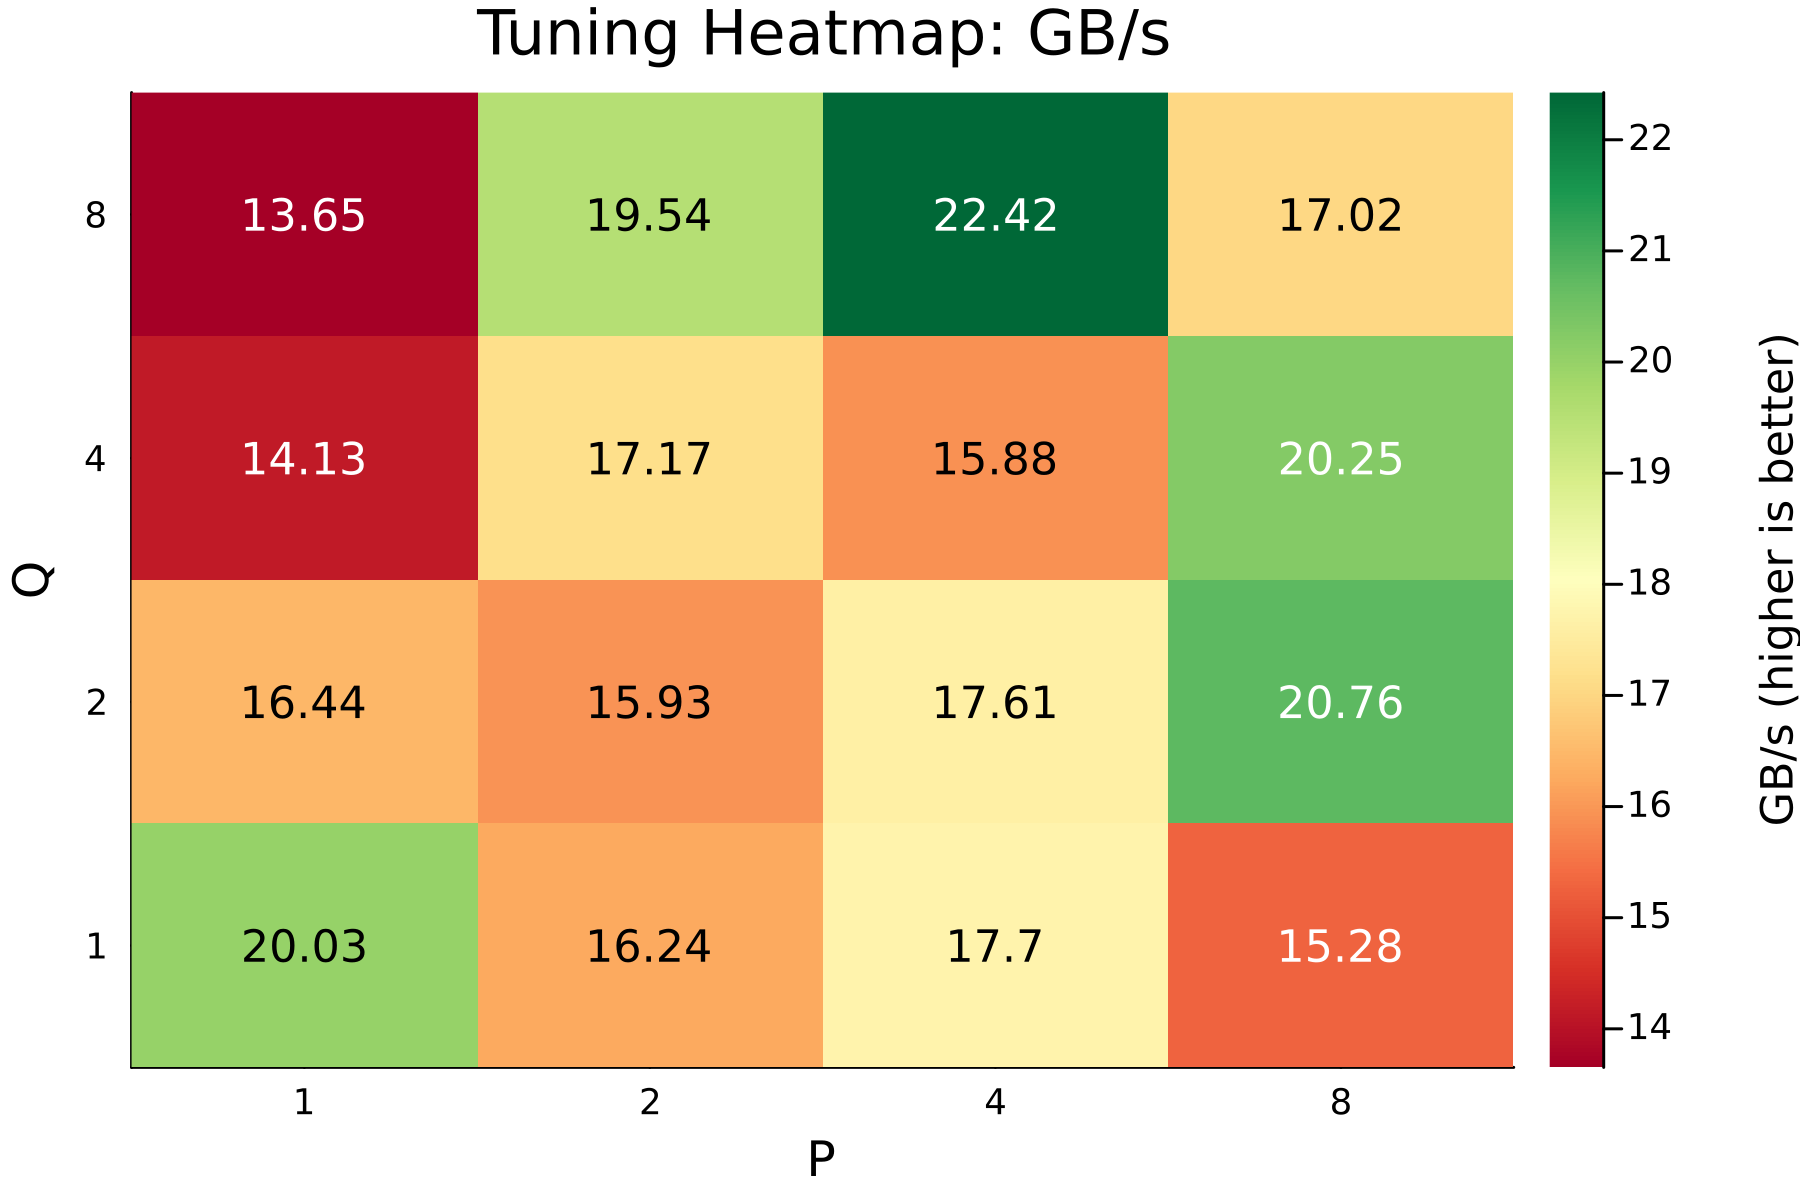

In [30]:
best = env_metrics["best_config"]
results_best_wg = filter(r -> r["block_size_x"] == best["block_size_x"] && r["block_size_y"] == best["block_size_y"], results_metrics)
plot_heatmap_tuning_results(results_best_wg, "P", "Q", "GB/s", true)

Compare the achieved bandwidth with the peak memory bandwidth of your GPU, which you can find in its specifications. If the best configuration stays far below the peak, the kernel is not limited by memory bandwidth. For a grid as small as 500 × 500, the GPU is not fully occupied. Note that Kernel Tuner measures the time the kernel runs on the GPU: in the simulation, the time to launch each kernel from the host comes on top of that, and for a kernel this short it can be as large as the kernel itself. A larger grid or several time steps per kernel launch then helps more than further tuning.

And the other way around, with `GFLOP/s` over the workgroup sizes given the best `P` and `Q`: 

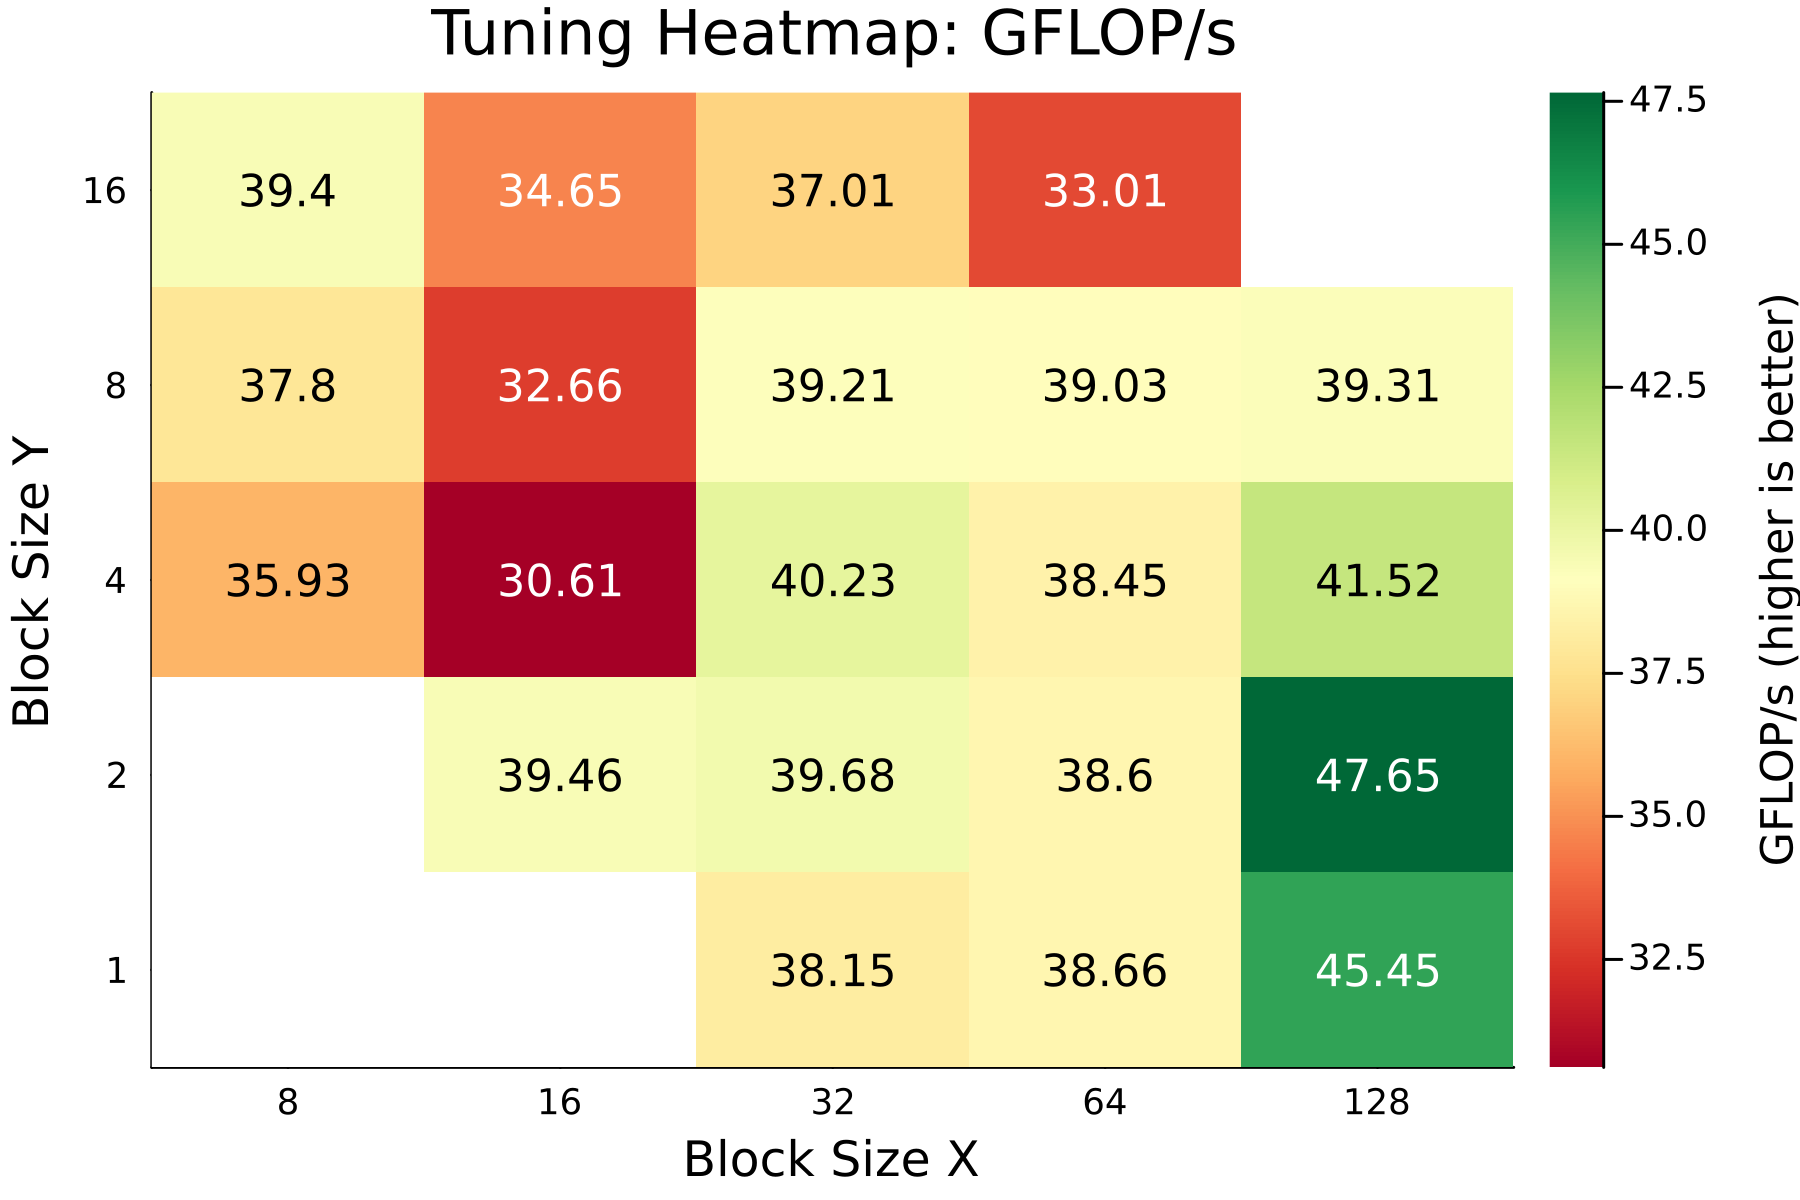

In [31]:
best = env_metrics["best_config"]
results_best_wg = filter(r -> r["P"] == best["P"] && r["Q"] == best["Q"], results_metrics)
plot_heatmap_tuning_results(results_best_wg, "block_size_x", "block_size_y", "GFLOP/s", true)

Metrics can also use the measurements of observers, for example the energy efficiency in GFLOP/J from the energy measured in Section 4.2.

# 5 All Combined

In Section 3.4 we tuned the workgroup and tile sizes together on the large search space, and in Section 4.2 we measured the energy on a small one. Let's combine the various concepts we've explored: we tune the large search space of Section 3.4 for energy with output verification, while a live plot shows the time and energy of each configuration as it is evaluated.

There is rarely a single best configuration for both time and energy. The black line in the plot is the *Pareto front*: the configurations for which no other configuration is both faster and uses less energy. Every configuration on the front is a sensible choice, and which one is best depends on how much you value time versus energy.

Measuring energy makes each configuration take longer to evaluate, as the energy observers measure each configuration for about a second. That's why we again use the optimization strategy and limits from Sections 3.2 and 3.3. We use a separate cache file, as the results cached in Section 3.4 contain no energy measurements. Configurations that are already in the cache are not measured again, so running the cell again adds new configurations to the plot.

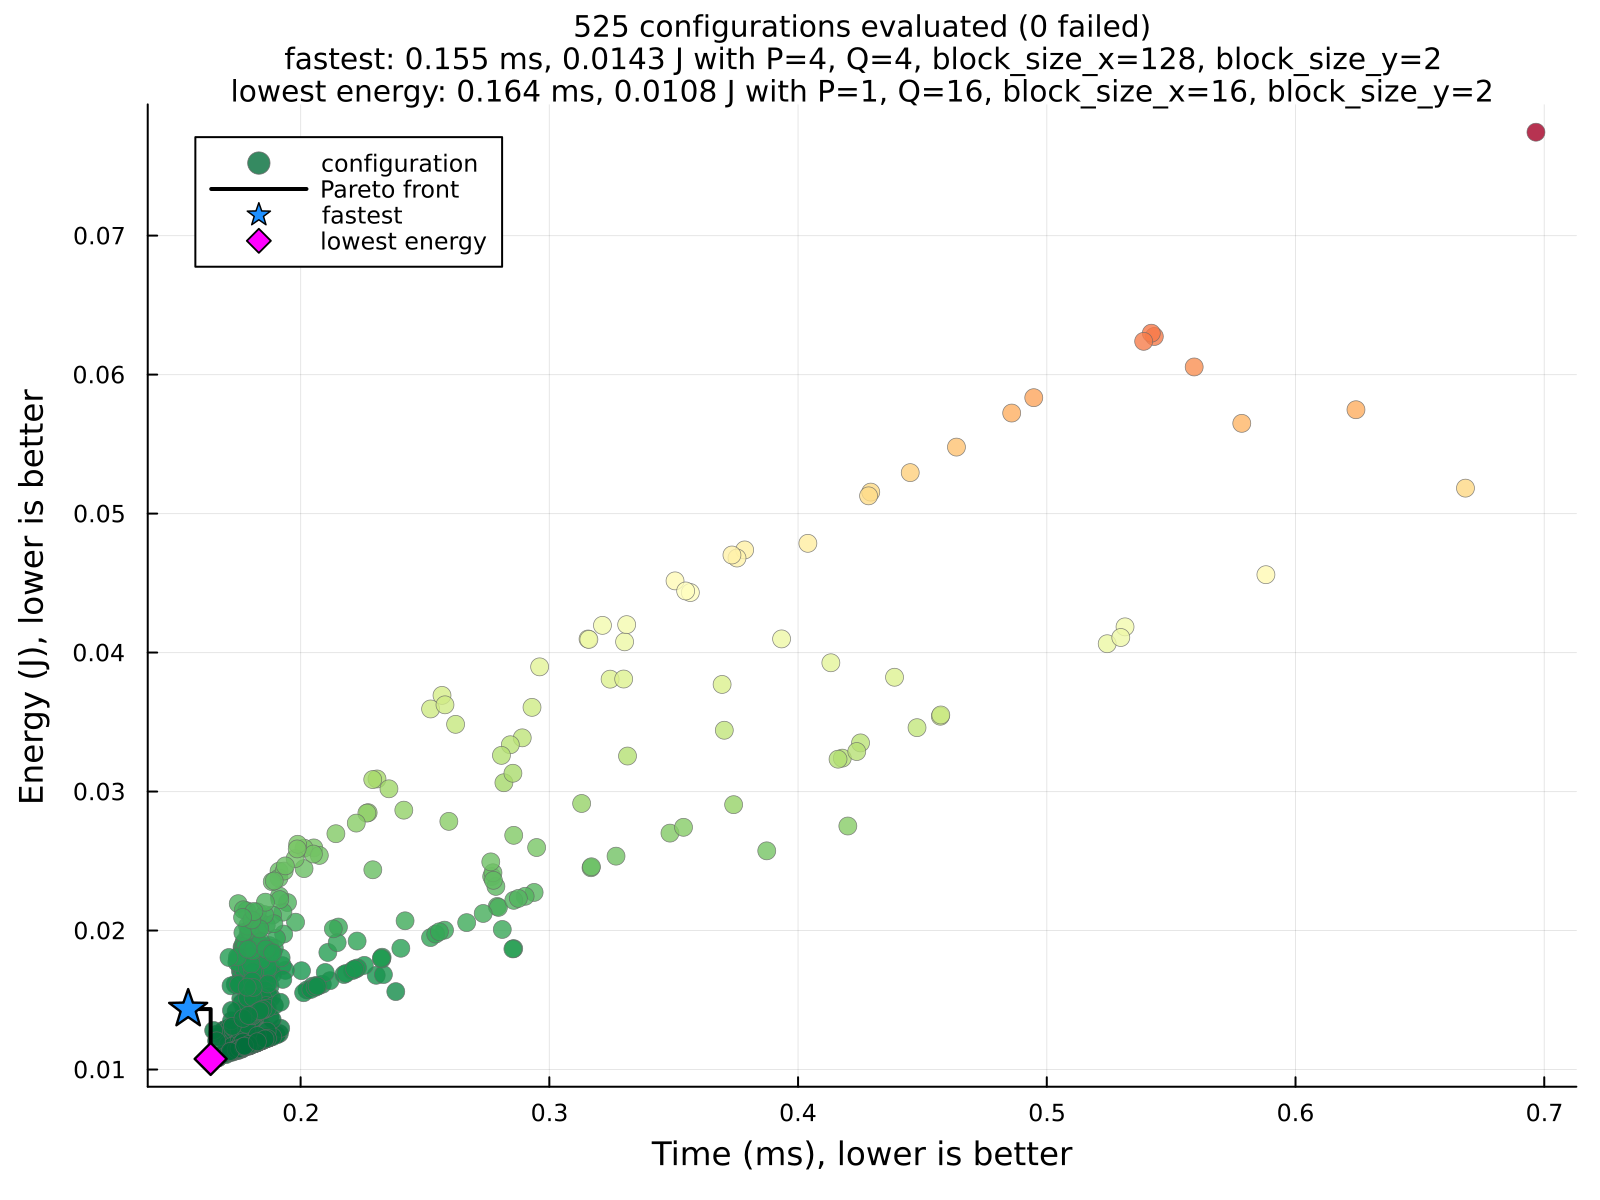

Using: NVIDIA RTX A6000
Searchspace has 525 configurations after restrictions.
P=1, Q=1, block_size_x=8, block_size_y=4, time=0.176ms
P=1, Q=1, block_size_x=8, block_size_y=8, time=0.167ms
P=1, Q=1, block_size_x=8, block_size_y=16, time=0.281ms
P=1, Q=1, block_size_x=16, block_size_y=2, time=0.169ms
P=1, Q=1, block_size_x=16, block_size_y=4, time=0.170ms
P=1, Q=1, block_size_x=16, block_size_y=8, time=0.167ms
P=1, Q=1, block_size_x=16, block_size_y=16, time=0.167ms
P=1, Q=1, block_size_x=32, block_size_y=1, time=0.172ms
P=1, Q=1, block_size_x=32, block_size_y=2, time=0.166ms
P=1, Q=1, block_size_x=32, block_size_y=4, time=0.167ms
P=1, Q=1, block_size_x=32, block_size_y=8, time=0.171ms
P=1, Q=1, block_size_x=32, block_size_y=16, time=0.175ms
P=1, Q=1, block_size_x=64, block_size_y=1, time=0.175ms
P=1, Q=1, block_size_x=64, block_size_y=2, time=0.174ms
P=1, Q=1, block_size_x=64, block_size_y=4, time=0.170ms
P=1, Q=1, block_size_x=64, block_size_y=8, time=0.173ms
P=1, Q=1, block_size_x=64

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:84: UserWarning: Measured GPU time 1.522 ms is more than 10x host time 0.115 ms; this may indicate an issue with the timing measurement. Replacing GPU time with host time for this measurement.
  warn(


P=2, Q=16, block_size_x=32, block_size_y=4, time=0.180ms
P=2, Q=16, block_size_x=32, block_size_y=8, time=0.186ms
P=2, Q=16, block_size_x=32, block_size_y=16, time=0.200ms
P=2, Q=16, block_size_x=64, block_size_y=1, time=0.179ms
P=2, Q=16, block_size_x=64, block_size_y=2, time=0.181ms
P=2, Q=16, block_size_x=64, block_size_y=4, time=0.179ms
P=2, Q=16, block_size_x=64, block_size_y=8, time=0.181ms
P=2, Q=16, block_size_x=64, block_size_y=16, time=0.206ms
P=2, Q=16, block_size_x=128, block_size_y=1, time=0.178ms
P=2, Q=16, block_size_x=128, block_size_y=2, time=0.188ms
P=2, Q=16, block_size_x=128, block_size_y=4, time=0.181ms
P=2, Q=16, block_size_x=128, block_size_y=8, time=0.185ms
P=4, Q=1, block_size_x=8, block_size_y=4, time=0.183ms
P=4, Q=1, block_size_x=8, block_size_y=8, time=0.183ms
P=4, Q=1, block_size_x=8, block_size_y=16, time=0.180ms
P=4, Q=1, block_size_x=16, block_size_y=2, time=0.181ms
P=4, Q=1, block_size_x=16, block_size_y=4, time=0.184ms
P=4, Q=1, block_size_x=16, block

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:84: UserWarning: Measured GPU time 1.654 ms is more than 10x host time 0.117 ms; this may indicate an issue with the timing measurement. Replacing GPU time with host time for this measurement.
  warn(


P=4, Q=16, block_size_x=64, block_size_y=4, time=0.205ms
P=4, Q=16, block_size_x=64, block_size_y=8, time=0.295ms
P=4, Q=16, block_size_x=64, block_size_y=16, time=0.267ms
P=4, Q=16, block_size_x=128, block_size_y=1, time=0.186ms
P=4, Q=16, block_size_x=128, block_size_y=2, time=0.187ms
P=4, Q=16, block_size_x=128, block_size_y=4, time=0.203ms
P=4, Q=16, block_size_x=128, block_size_y=8, time=0.223ms
P=8, Q=1, block_size_x=8, block_size_y=4, time=0.181ms
P=8, Q=1, block_size_x=8, block_size_y=8, time=0.188ms
P=8, Q=1, block_size_x=8, block_size_y=16, time=0.277ms
P=8, Q=1, block_size_x=16, block_size_y=2, time=0.186ms
P=8, Q=1, block_size_x=16, block_size_y=4, time=0.181ms
P=8, Q=1, block_size_x=16, block_size_y=8, time=0.188ms
P=8, Q=1, block_size_x=16, block_size_y=16, time=0.188ms
P=8, Q=1, block_size_x=32, block_size_y=1, time=0.184ms
P=8, Q=1, block_size_x=32, block_size_y=2, time=0.193ms
P=8, Q=1, block_size_x=32, block_size_y=4, time=0.278ms
P=8, Q=1, block_size_x=32, block_size

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:95: UserWarning: Measured GPU time 1.747 ms is substantially greater than host time 0.190 ms; this may indicate an issue with the timing measurement.
  warn(


P=8, Q=8, block_size_x=32, block_size_y=1, time=0.205ms
P=8, Q=8, block_size_x=32, block_size_y=2, time=0.207ms
P=8, Q=8, block_size_x=32, block_size_y=4, time=0.212ms
P=8, Q=8, block_size_x=32, block_size_y=8, time=0.227ms
P=8, Q=8, block_size_x=32, block_size_y=16, time=0.257ms
P=8, Q=8, block_size_x=64, block_size_y=1, time=0.206ms
P=8, Q=8, block_size_x=64, block_size_y=2, time=0.210ms
P=8, Q=8, block_size_x=64, block_size_y=4, time=0.222ms
P=8, Q=8, block_size_x=64, block_size_y=8, time=0.252ms
P=8, Q=8, block_size_x=64, block_size_y=16, time=0.348ms
P=8, Q=8, block_size_x=128, block_size_y=1, time=0.207ms
P=8, Q=8, block_size_x=128, block_size_y=2, time=0.213ms
P=8, Q=8, block_size_x=128, block_size_y=4, time=0.285ms
P=8, Q=8, block_size_x=128, block_size_y=8, time=0.280ms
P=8, Q=16, block_size_x=8, block_size_y=4, time=0.262ms
P=8, Q=16, block_size_x=8, block_size_y=8, time=0.296ms
P=8, Q=16, block_size_x=8, block_size_y=16, time=0.317ms
P=8, Q=16, block_size_x=16, block_size_y=

/home/fjwillem/Code/kernel_tuner/kernel_tuner/observers/julia.py:84: UserWarning: Measured GPU time 1.688 ms is more than 10x host time 0.122 ms; this may indicate an issue with the timing measurement. Replacing GPU time with host time for this measurement.
  warn(


P=16, Q=1, block_size_x=64, block_size_y=16, time=0.181ms
P=16, Q=1, block_size_x=128, block_size_y=1, time=0.179ms
P=16, Q=1, block_size_x=128, block_size_y=2, time=0.172ms
P=16, Q=1, block_size_x=128, block_size_y=4, time=0.177ms
P=16, Q=1, block_size_x=128, block_size_y=8, time=0.183ms
P=16, Q=2, block_size_x=8, block_size_y=4, time=0.186ms
P=16, Q=2, block_size_x=8, block_size_y=8, time=0.189ms
P=16, Q=2, block_size_x=8, block_size_y=16, time=0.187ms
P=16, Q=2, block_size_x=16, block_size_y=2, time=0.183ms
P=16, Q=2, block_size_x=16, block_size_y=4, time=0.184ms
P=16, Q=2, block_size_x=16, block_size_y=8, time=0.185ms
P=16, Q=2, block_size_x=16, block_size_y=16, time=0.192ms
P=16, Q=2, block_size_x=32, block_size_y=1, time=0.177ms
P=16, Q=2, block_size_x=32, block_size_y=2, time=0.184ms
P=16, Q=2, block_size_x=32, block_size_y=4, time=0.179ms
P=16, Q=2, block_size_x=32, block_size_y=8, time=0.189ms
P=16, Q=2, block_size_x=32, block_size_y=16, time=0.193ms
P=16, Q=2, block_size_x=64

(Dict{String, Any}[Dict("compile_time" => 33.00167992711067, "Q" => 1, "time" => 0.1763040005850295, "P" => 1, "times" => [0.1822720078052953, 0.18636800814419985, 0.19456000882200897, 0.17612800002098083, 0.16588799189776182, 0.16793599934317172, 0.16694399528205395], "core_freq" => 1800.0, "temperature" => 35.0, "nvml_energy" => 0.011462051990034524, "verification_time" => 634.6752713434398, "benchmark_time" => 4561.292535159737…), Dict("compile_time" => 32.99934510141611, "Q" => 1, "time" => 0.16743999731261283, "P" => 1, "times" => [0.16793599934317172, 0.17417599156033248, 0.16383999900426716, 0.17715198919177055, 0.1648640027269721, 0.1597439986653626, 0.1648640027269721], "core_freq" => 1800.0, "temperature" => 35.0, "nvml_energy" => 0.012340411521938223, "verification_time" => 634.9154501222074, "benchmark_time" => 1004.116372205317…), Dict("compile_time" => 44.8617460206151, "Q" => 1, "time" => 0.28108799597248435, "P" => 1, "times" => [0.2703359932638705, 0.2775040047708899, 

In [32]:
# the same observer as in Section 4.2; the name of the energy field differs per vendor
energy_observer, energy_fields = KernelTuner.get_energy_observer_for_backend("default")
energy_key = only(filter(endswith("energy"), energy_fields))

# reference output: one step of the simple kernel, run on the CPU
U_ref, V_ref = copy(U), copy(V)
gs_gpu_kernel!(CPU(), (16, 16))(U_ref, V_ref, U, V, 0.16f0, 0.08f0, 0.035f0, 0.06f0, 1.0f0, 1.0f0, n, n, 0.0f0, ndrange=(n, n))

# one entry per kernel argument: check Uout and Vout, skip the rest
answer = [U_ref, V_ref, fill(nothing, length(arguments) - 2)...]

cachefile_energy = "gs_gpu_kernel_tuned_energy.json"

# the plot of time versus energy is redrawn as configurations are added to the cache file
results_combined, env_combined = with_live_tuning_plot(cachefile_energy; plotter=plot_live_time_energy, energy_key=energy_key) do
    KernelTuner.tune_kernel(
        "gs_gpu_kernel_tiled!",
        get_cell_by_tag("gs_gpu_kernel_tiled"),
        (n, n),
        arguments,
        tune_params,                    # the large search space of Section 3.4
        restrictions=restrictions,
        grid_div_x=("block_size_x", "Q"), grid_div_y=("block_size_y", "P"),
        lang="Julia",
        observers=[energy_observer],
        objective=energy_key,           # the strategy minimizes energy, the plot shows both time and energy
        objective_higher_is_better=true,
        cache=cachefile_energy,
        answer=answer,
        atol=1e-5,  # maximum absolute difference allowed, the GPU and CPU may round slightly differently
        verbose=true,
    )
end

# if you'd like to start over without the cached results, uncomment the following line
# rm(cachefile_energy)

Finally, let's list the configurations on the Pareto front, from fastest to most energy-efficient:

In [33]:
measured(r) = all(k -> get(r, k, nothing) isa Real && r[k] > 0, ("time", energy_key))   # skip failed configurations
results_measured = filter(measured, results_combined)
front = pareto_front([r["time"] for r in results_measured], [r[energy_key] for r in results_measured])   # defined in the setup

most_performant = first(results_measured[front])
for r in results_measured[front]
    params = join(["$k=$(r[k])" for k in first.(tune_params)], ", ")
    time_saved = 100 * (most_performant["time"] - r["time"]) / most_performant["time"]
    energy_saved = 100 * (most_performant[energy_key] - r[energy_key]) / most_performant[energy_key]
    if r == most_performant
        savings_string = ""
    else
        savings_string = time_saved > 0 ? "saves $(round(time_saved, sigdigits=3))% time" : "trades $(round(-time_saved, sigdigits=3))% time"
        savings_string *= energy_saved > 0 ? " to save $(round(energy_saved, sigdigits=3))% energy" : " by trading $(round(-energy_saved, sigdigits=3))% energy"
    end
    println(params, "  ($(round(r["time"], digits=3)) ms, $(round(r[energy_key], sigdigits=3)) J); $savings_string")
end

P=4, Q=4, block_size_x=128, block_size_y=2  (0.155 ms, 0.0143 J); 
P=1, Q=16, block_size_x=16, block_size_y=2  (0.164 ms, 0.0108 J); trades 5.84% time to save 25.0% energy


If you are limited by the time to solution, pick the configuration at the fast end of the front; if you are limited by an energy or power budget, pick one further along. Configurations far above the front are worse in both respects and can be discarded. Keep in mind that, like the timings, energy measurements are noisy, especially for kernels that take well under a millisecond.